
# Road Damage Analytics and Automated Detection Using Deep Learning

## 1. Project Overview

Road infrastructure plays an important role in transportation safety and urban development. Damaged road surfaces, particularly potholes, can cause vehicle damage, traffic disruptions, and accidents. Manual road inspection is time-consuming and requires continuous human effort.

This project focuses on developing an automated road damage detection system using deep learning and computer vision. The objective is to identify potholes in road images and localize them using bounding boxes.

A Faster R-CNN object detection model with a ResNet-50 Feature Pyramid Network (FPN) backbone is implemented using PyTorch and Torchvision. The model is initialized with pretrained COCO weights, and its classification head is modified to detect the target pothole class.

Two experiments are conducted:

1. **Experiment 1 – Baseline:** Faster R-CNN trained using the original training images.
2. **Experiment 2 – Data Augmentation:** Faster R-CNN trained using randomly augmented training images.

The experiments are compared using validation metrics. The best-performing checkpoint is selected based on validation mAP@50–95 and evaluated on an untouched test set.

The project also examines prediction visualizations, inference time, model parameters, and checkpoint size.

## 1.1 Project Objectives

- Develop an object detection model for pothole identification.
- Process road images and their corresponding bounding-box annotations.
- Implement Faster R-CNN using transfer learning.
- Investigate the effect of data augmentation on detection performance.
- Compare baseline and augmented training experiments.
- Evaluate the selected model on an independent test set.
- Analyze model efficiency through inference time and parameter count.
- Visualize detected potholes and compare predictions with ground-truth annotations.

## 1.2 Technologies Used

- Python
- PyTorch
- Torchvision
- NumPy and Pandas
- Matplotlib
- Pillow
- TorchMetrics
- Google Colab
- Google Drive



# 2. Environment Setup

The project is implemented in Python using Google Colab. PyTorch and Torchvision are used to construct, train, and evaluate the Faster R-CNN object detection model.

Additional libraries are used for image processing, annotation parsing, numerical operations, visualization, and evaluation.

The training experiments were conducted using a Tesla T4 GPU. The final evaluation and additional inference-time measurements were performed in a CPU-only runtime.

The notebook checks the installed library versions and CUDA availability to identify the execution environment.

**Note:** The runtime hardware can change when reconnecting to Google Colab. The final test metrics reported in this notebook are from the completed final evaluation, not from a repeated evaluation in a different runtime.


In [ ]:
import sys
print("Python version:", sys.version)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
if torch.cuda.is_available():
    print("Total GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

Total GPU memory: 14.56 GB


In [ ]:
import torchvision
print("Torchvision version:", torchvision.__version__)

Torchvision version: 0.29.1+cu130


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import PIL
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow:", PIL.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
Pillow: 11.3.0
Scikit-learn: 1.6.1


In [ ]:

try:
    import torchmetrics
    print("TorchMetrics:", torchmetrics.__version__)
except ImportError:
    print("TorchMetrics: Not installed")

TorchMetrics: Not installed


In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 9.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [ ]:
import torchmetrics
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("TorchMetrics:", torchmetrics.__version__)
print("MeanAveragePrecision imported successfully!")

TorchMetrics: 1.9.0
MeanAveragePrecision imported successfully!


In [ ]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

print("Faster R-CNN imports successful!")

Faster R-CNN imports successful!



# 3. Dataset Description

The project uses an annotated road damage image dataset containing road images and their corresponding object annotations.

The annotations are provided in Pascal VOC XML format. Each annotation contains the object class and bounding-box coordinates representing the location of the pothole in the image.

The dataset is organized into three subsets:

| Dataset Split | Number of Images |
|---|---:|
| Training | 426 |
| Validation | 106 |
| Testing | 133 |
| **Total** | **665** |

## 3.1 Dataset Structure

The dataset is stored in Google Drive with the following directory organization:

- `images/` – Contains road images separated into training, validation, and test folders.
- `annotations/` – Contains corresponding Pascal VOC XML annotation files.
- `split_manifest.json` – Records the dataset split assignments.
- `labels/` – Contains additional label-related files.
- `yolo_dataset/` – Contains the YOLO-format dataset organization.

The object detection task in this implementation focuses on a single class:

- Pothole

The dataset split was generated using random seed 42, with the original test split preserved. The split manifest is used to verify that the image and annotation assignments are consistent and that the subsets do not overlap.

The test set is kept separate from model training and validation-based model selection.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/road_data_shared"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset path:", DATASET_PATH)

Dataset exists: True
Dataset path: /content/drive/MyDrive/road_data_shared


In [ ]:
for item in sorted(os.listdir(DATASET_PATH)):
    path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(path):
        print(f"[DIR]  {item}")
    else:
        print(f"[FILE] {item}")

[DIR]  annotations
[DIR]  images
[DIR]  labels
[FILE] split_manifest.json
[DIR]  yolo_dataset


In [ ]:
for folder in ["images", "annotations"]:
    print(f"\n{folder.upper()}")

    folder_path = os.path.join(DATASET_PATH, folder)

    for split in sorted(os.listdir(folder_path)):
        split_path = os.path.join(folder_path, split)

        if os.path.isdir(split_path):
            print(f"  {split}: {len(os.listdir(split_path))} files")


IMAGES
  test: 133 files
  train: 426 files
  val: 106 files

ANNOTATIONS
  test: 133 files
  train: 426 files
  val: 106 files


In [ ]:
image_extensions = (".jpg", ".jpeg", ".png")

for split in ["train", "val", "test"]:
    image_dir = os.path.join(DATASET_PATH, "images", split)
    annotation_dir = os.path.join(DATASET_PATH, "annotations", split)

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(image_extensions)
    ]

    xml_files = [
        f for f in os.listdir(annotation_dir)
        if f.lower().endswith(".xml")
    ]

    print(f"{split.upper()}:")
    print("  Images:", len(images))
    print("  XML annotations:", len(xml_files))

TRAIN:
  Images: 426
  XML annotations: 426
VAL:
  Images: 106
  XML annotations: 106
TEST:
  Images: 133
  XML annotations: 133


In [ ]:
import json

manifest_path = os.path.join(DATASET_PATH, "split_manifest.json")

with open(manifest_path, "r") as f:
    manifest = json.load(f)

print(json.dumps(manifest, indent=2)[:5000])

{
  "seed": 42,
  "source_split": "Original 80/20 split; original test set preserved",
  "train": [
    "img-1.xml",
    "img-100.xml",
    "img-101.xml",
    "img-103.xml",
    "img-105.xml",
    "img-106.xml",
    "img-110.xml",
    "img-111.xml",
    "img-112.xml",
    "img-113.xml",
    "img-116.xml",
    "img-119.xml",
    "img-12.xml",
    "img-123.xml",
    "img-125.xml",
    "img-126.xml",
    "img-128.xml",
    "img-13.xml",
    "img-130.xml",
    "img-132.xml",
    "img-134.xml",
    "img-135.xml",
    "img-136.xml",
    "img-139.xml",
    "img-14.xml",
    "img-142.xml",
    "img-144.xml",
    "img-145.xml",
    "img-148.xml",
    "img-149.xml",
    "img-15.xml",
    "img-150.xml",
    "img-153.xml",
    "img-154.xml",
    "img-157.xml",
    "img-158.xml",
    "img-160.xml",
    "img-162.xml",
    "img-163.xml",
    "img-165.xml",
    "img-166.xml",
    "img-167.xml",
    "img-168.xml",
    "img-170.xml",
    "img-171.xml",
    "img-172.xml",
    "img-174.xml",
    "img-175.


## 3.2 Dataset Integrity and Split Verification

Before model development, the dataset organization and annotation consistency are examined.

The following checks are performed:

- Number of images and annotation files in each split.
- Matching image and annotation filenames.
- Consistency between the split manifest and actual annotation files.
- Overlap between training, validation, and test subsets.
- Correct organization of the dataset folders.

The split manifest is used to confirm that the training, validation, and test subsets contain distinct samples.

These checks help prevent accidental data leakage between the different stages of model development.


In [ ]:
for split in ["train", "val", "test"]:
    image_dir = os.path.join(DATASET_PATH, "images", split)
    annotation_dir = os.path.join(DATASET_PATH, "annotations", split)

    image_names = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    xml_names = {
        os.path.splitext(f)[0]
        for f in os.listdir(annotation_dir)
        if f.lower().endswith(".xml")
    }

    print(f"\n{split.upper()}")
    print("Images without XML:", sorted(image_names - xml_names)[:10])
    print("XML without image:", sorted(xml_names - image_names)[:10])
    print("Exact matches:", image_names == xml_names)


TRAIN
Images without XML: []
XML without image: []
Exact matches: True

VAL
Images without XML: []
XML without image: []
Exact matches: True

TEST
Images without XML: []
XML without image: []
Exact matches: True


In [ ]:
split_sets = {
    split: set(manifest[split])
    for split in ["train", "val", "test"]
}

for split, files in split_sets.items():
    print(f"{split}: {len(files)}")

print("\nTrain-Val overlap:", len(split_sets["train"] & split_sets["val"]))
print("Train-Test overlap:", len(split_sets["train"] & split_sets["test"]))
print("Val-Test overlap:", len(split_sets["val"] & split_sets["test"]))

train: 426
val: 106
test: 133

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
for split in ["train", "val", "test"]:
    actual_xml = set(os.listdir(
        os.path.join(DATASET_PATH, "annotations", split)
    ))

    manifest_xml = set(manifest[split])

    print(f"\n{split.upper()}")
    print("Missing from folder:", len(manifest_xml - actual_xml))
    print("Not in manifest:", len(actual_xml - manifest_xml))


TRAIN
Missing from folder: 0
Not in manifest: 0

VAL
Missing from folder: 0
Not in manifest: 0

TEST
Missing from folder: 0
Not in manifest: 0



# 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the image dataset and its annotations before training the object detection model.

The analysis focuses on:

1. Distribution of pothole annotations across the dataset splits.
2. Number of objects present in each image.
3. Images containing empty or invalid annotations.
4. Image dimensions and variations in resolution.
5. Visual inspection of road images and bounding-box annotations.

## 4.1 Annotation Format

The annotations are stored in Pascal VOC XML format.

Each XML file contains information such as:

- Image filename.
- Image width and height.
- Object class name.
- Bounding-box coordinates: `xmin`, `ymin`, `xmax`, and `ymax`.

The bounding-box coordinates represent the rectangular region containing the pothole.

## 4.2 Class Distribution

The dataset contains one target object class: pothole.

The number of annotated pothole instances is examined separately for the training, validation, and test subsets.

This provides an understanding of the number of available training examples and the distribution of annotated objects across the dataset.


In [ ]:
import xml.etree.ElementTree as ET

xml_path = os.path.join(
    DATASET_PATH, "annotations", "train", "img-100.xml"
)

tree = ET.parse(xml_path)
root = tree.getroot()

print(ET.tostring(root, encoding="unicode"))

<annotation>
	<folder>dataset</folder>
	<filename>img-100.jpg</filename>
	<path>/CSE-800/Thesis/2020-01-23/dataset/img-100.jpg</path>
	<source>
		<database>Unknown</database>
	</source>
	<size>
		<width>720</width>
		<height>720</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>pothole</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>235</xmin>
			<ymin>272</ymin>
			<xmax>434</xmax>
			<ymax>388</ymax>
		</bndbox>
	</object>
</annotation>


In [ ]:
from collections import Counter

for split in ["train", "val", "test"]:
    annotation_dir = os.path.join(DATASET_PATH, "annotations", split)

    class_counts = Counter()
    total_objects = 0
    empty_annotations = 0

    for filename in os.listdir(annotation_dir):
        if not filename.endswith(".xml"):
            continue

        root = ET.parse(os.path.join(annotation_dir, filename)).getroot()
        objects = root.findall("object")

        if len(objects) == 0:
            empty_annotations += 1

        for obj in objects:
            class_name = obj.findtext("name", default="UNKNOWN").strip().lower()
            class_counts[class_name] += 1
            total_objects += 1

    print(f"\n{split.upper()}")
    print("Total objects:", total_objects)
    print("Class distribution:", dict(class_counts))
    print("Images with no objects:", empty_annotations)


TRAIN
Total objects: 1173
Class distribution: {'pothole': 1173}
Images with no objects: 0

VAL
Total objects: 268
Class distribution: {'pothole': 268}
Images with no objects: 0

TEST
Total objects: 299
Class distribution: {'pothole': 299}
Images with no objects: 0



## 4.3 Dataset Quality Observations

The annotation inspection produced the following observations:

| Split | Number of Images | Pothole Instances |
|---|---:|---:|
| Training | 426 | 1,173 |
| Validation | 106 | 268 |
| Testing | 133 | 299 |

The training annotations contain one invalid bounding box in `img-415.xml`, where the bounding-box width is zero. This annotation is skipped during dataset loading.

The remaining bounding boxes are checked for valid coordinate ordering and positive width and height.

No empty annotations were found in the three dataset splits.

The image dimensions vary across the dataset. The Faster R-CNN implementation handles image resizing internally while preserving the aspect ratio.

## 4.4 Visual Inspection

Sample images are displayed along with their ground-truth bounding boxes.

This visual inspection helps verify that the XML annotations correspond to the pothole regions in the road images.

Images containing multiple potholes are also examined to understand how the object detection model should handle multiple instances within a single image.

**Observation:** The dataset contains variations in road texture, lighting, image resolution, pothole size, and background appearance. These variations make pothole detection a challenging object detection task.


In [ ]:
from PIL import Image

for split in ["train", "val", "test"]:
    image_dir = os.path.join(DATASET_PATH, "images", split)
    annotation_dir = os.path.join(DATASET_PATH, "annotations", split)

    invalid_boxes = []
    dimension_mismatches = []
    malformed_boxes = []

    for filename in os.listdir(annotation_dir):
        if not filename.endswith(".xml"):
            continue

        image_path = os.path.join(image_dir, filename.replace(".xml", ".jpg"))
        # Resolve image extension from matching filename
        image_stem = os.path.splitext(filename)[0]
        matching_images = [
            f for f in os.listdir(image_dir)
            if os.path.splitext(f)[0] == image_stem
        ]

        if not matching_images:
            continue

        image_path = os.path.join(image_dir, matching_images[0])

        with Image.open(image_path) as img:
            actual_width, actual_height = img.size

        root = ET.parse(os.path.join(annotation_dir, filename)).getroot()

        xml_width = int(root.findtext("size/width"))
        xml_height = int(root.findtext("size/height"))

        if (xml_width, xml_height) != (actual_width, actual_height):
            dimension_mismatches.append(filename)

        for obj in root.findall("object"):
            bbox = obj.find("bndbox")

            try:
                xmin = float(bbox.findtext("xmin"))
                ymin = float(bbox.findtext("ymin"))
                xmax = float(bbox.findtext("xmax"))
                ymax = float(bbox.findtext("ymax"))

                if not (
                    0 <= xmin < xmax <= actual_width
                    and 0 <= ymin < ymax <= actual_height
                ):
                    invalid_boxes.append((filename, [xmin, ymin, xmax, ymax]))

            except (TypeError, ValueError):
                malformed_boxes.append(filename)

    print(f"\n{split.upper()}")
    print("Invalid boxes:", len(invalid_boxes))
    print("Malformed boxes:", len(malformed_boxes))
    print("Dimension mismatches:", len(dimension_mismatches))
    print("Invalid box examples:", invalid_boxes[:5])


TRAIN
Invalid boxes: 1
Malformed boxes: 0
Dimension mismatches: 0
Invalid box examples: [('img-415.xml', [273.0, 164.0, 273.0, 165.0])]

VAL
Invalid boxes: 0
Malformed boxes: 0
Dimension mismatches: 0
Invalid box examples: []

TEST
Invalid boxes: 0
Malformed boxes: 0
Dimension mismatches: 0
Invalid box examples: []


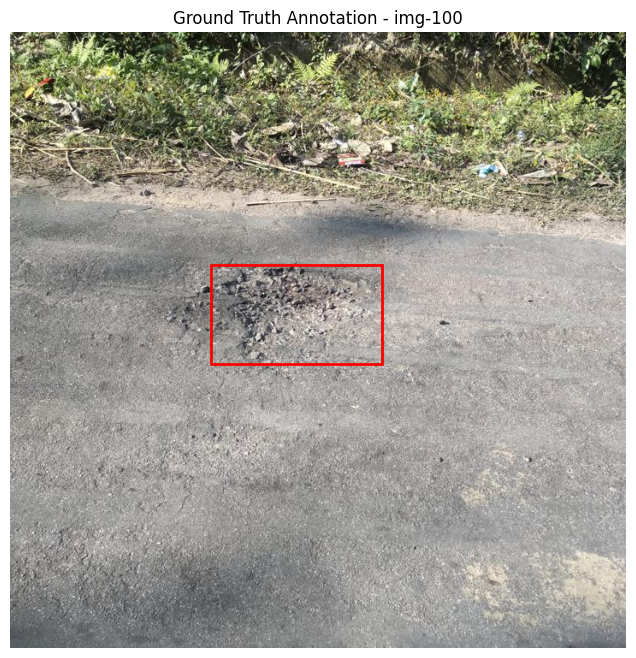

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import xml.etree.ElementTree as ET
import os

image_name = "img-100.jpg"

image_path = os.path.join(
    DATASET_PATH, "images", "train", image_name
)

xml_path = os.path.join(
    DATASET_PATH, "annotations", "train", "img-100.xml"
)

image = Image.open(image_path).convert("RGB")
root = ET.parse(xml_path).getroot()

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image)

for obj in root.findall("object"):
    bbox = obj.find("bndbox")

    xmin = float(bbox.findtext("xmin"))
    ymin = float(bbox.findtext("ymin"))
    xmax = float(bbox.findtext("xmax"))
    ymax = float(bbox.findtext("ymax"))

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

plt.title("Ground Truth Annotation - img-100")
plt.axis("off")
plt.show()

In [ ]:
multi_image = None

for filename in sorted(os.listdir(
    os.path.join(DATASET_PATH, "annotations", "train")
)):
    root = ET.parse(os.path.join(
        DATASET_PATH, "annotations", "train", filename
    )).getroot()

    if len(root.findall("object")) >= 3:
        multi_image = filename.replace(".xml", ".jpg")
        break

print("Selected image:", multi_image)

Selected image: img-111.jpg


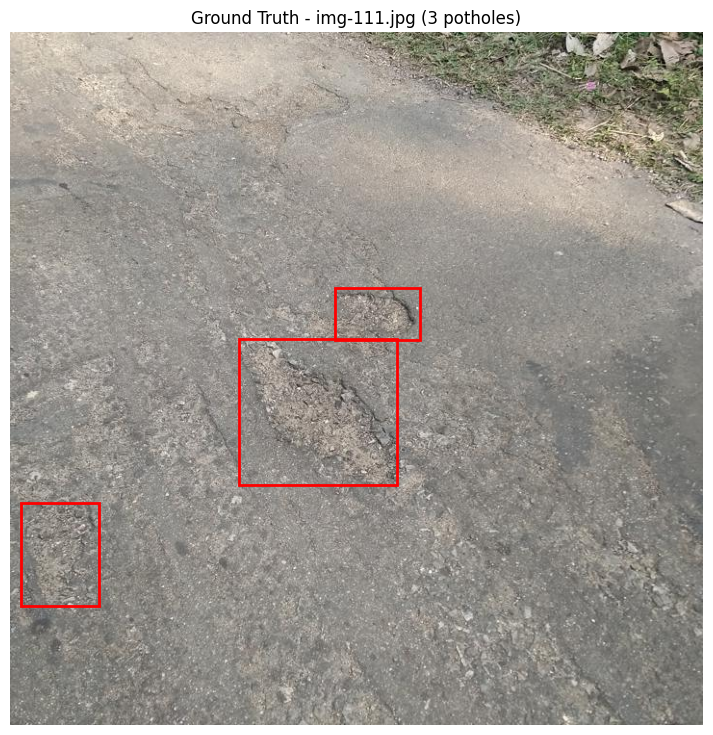

In [ ]:
image_name = multi_image

image_path = os.path.join(
    DATASET_PATH, "images", "train", image_name
)

xml_path = os.path.join(
    DATASET_PATH, "annotations", "train",
    image_name.replace(".jpg", ".xml")
)

image = Image.open(image_path).convert("RGB")
root = ET.parse(xml_path).getroot()

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(image)

for obj in root.findall("object"):
    bbox = obj.find("bndbox")

    xmin = float(bbox.findtext("xmin"))
    ymin = float(bbox.findtext("ymin"))
    xmax = float(bbox.findtext("xmax"))
    ymax = float(bbox.findtext("ymax"))

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(f"Ground Truth - {image_name} ({len(root.findall('object'))} potholes)")
ax.axis("off")
plt.show()


# 5. Data Preprocessing

Before training, the road images and XML annotations are converted into the format expected by Torchvision's Faster R-CNN implementation.

The preprocessing pipeline consists of the following steps:

1. Read the road image and convert it to RGB format.
2. Parse the corresponding Pascal VOC XML annotation.
3. Extract the pothole bounding-box coordinates.
4. Convert the coordinates into the format `[xmin, ymin, xmax, ymax]`.
5. Assign class label `1` to pothole objects, reserving label `0` for the background.
6. Convert images into PyTorch tensors.
7. Construct the target dictionary required by Faster R-CNN.

Each target contains:

- `boxes`: Bounding-box coordinates.
- `labels`: Object class labels.
- `image_id`: Image identifier.
- `area`: Area of each bounding box.
- `iscrowd`: Crowd annotation indicator.

Invalid bounding boxes with non-positive width or height are skipped during loading.

## 5.1 Dataset Splitting

The dataset is divided into training, validation, and test subsets.

- Training data is used to optimize model parameters.
- Validation data is used to monitor performance and select the best checkpoint.
- Test data is reserved for final performance evaluation.

The original test split is preserved throughout the experiments to ensure an independent final evaluation.


In [ ]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seeds configured:", SEED)

Random seeds configured: 42


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Using device: cuda
GPU: Tesla T4


In [ ]:
from PIL import Image
import os

image_dir = os.path.join(DATASET_PATH, "images", "train")

image_sizes = {}

for filename in os.listdir(image_dir):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        with Image.open(os.path.join(image_dir, filename)) as img:
            image_sizes[img.size] = image_sizes.get(img.size, 0) + 1

print("Training image dimensions:", image_sizes)

Training image dimensions: {(720, 720): 181, (300, 442): 2, (401, 300): 5, (449, 300): 5, (533, 300): 34, (534, 300): 7, (544, 300): 3, (453, 300): 3, (400, 300): 42, (300, 444): 1, (300, 300): 4, (574, 300): 1, (688, 300): 1, (451, 300): 7, (442, 300): 2, (458, 300): 1, (571, 300): 2, (450, 300): 37, (489, 300): 1, (503, 300): 2, (345, 300): 1, (480, 300): 3, (540, 300): 2, (536, 300): 1, (600, 300): 4, (482, 300): 2, (366, 300): 1, (362, 300): 1, (300, 403): 1, (300, 400): 9, (418, 300): 1, (452, 300): 1, (402, 300): 1, (695, 300): 1, (479, 300): 1, (425, 300): 2, (530, 300): 1, (467, 300): 1, (447, 300): 3, (684, 300): 1, (527, 300): 1, (439, 300): 1, (443, 300): 1, (300, 356): 1, (396, 300): 1, (455, 300): 2, (470, 300): 1, (381, 300): 1, (720, 280): 1, (716, 300): 1, (481, 300): 2, (382, 300): 1, (510, 300): 1, (427, 300): 1, (460, 300): 1, (463, 300): 1, (465, 300): 1, (300, 451): 1, (520, 300): 1, (720, 251): 1, (407, 300): 1, (583, 300): 1, (509, 300): 1, (300, 450): 1, (532, 3


## 5.2 Custom PyTorch Dataset

A custom PyTorch Dataset class named `RoadDamageDataset` is implemented to load road images and their corresponding XML annotations.

The class provides image tensors and target dictionaries in the format required by Faster R-CNN.

This approach allows the model to process images containing different numbers of pothole instances.

## 5.3 DataLoaders

PyTorch DataLoaders are used to load the dataset in batches.

The batch size is set to 2 due to the computational requirements of Faster R-CNN.

A custom `collate_fn` is used because object detection images may contain different numbers of bounding boxes. Unlike conventional image classification, the targets cannot be directly stacked into a single fixed-size tensor.

The DataLoaders are configured separately for training, validation, and testing.


In [ ]:
import os
import torch
import xml.etree.ElementTree as ET

from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import functional as F


class RoadDamageDataset(Dataset):

    def __init__(self, root_dir, split):

        self.image_dir = os.path.join(root_dir, "images", split)
        self.annotation_dir = os.path.join(root_dir, "annotations", split)

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        self.records = []
        self.invalid_annotations = []

        for image_name in self.image_files:

            xml_name = os.path.splitext(image_name)[0] + ".xml"
            xml_path = os.path.join(self.annotation_dir, xml_name)

            root = ET.parse(xml_path).getroot()

            boxes = []
            labels = []

            for obj in root.findall("object"):

                class_name = obj.findtext("name", "").strip().lower()

                if class_name != "pothole":
                    raise ValueError(
                        f"Unexpected class {class_name} in {xml_name}"
                    )

                bbox = obj.find("bndbox")

                xmin = float(bbox.findtext("xmin"))
                ymin = float(bbox.findtext("ymin"))
                xmax = float(bbox.findtext("xmax"))
                ymax = float(bbox.findtext("ymax"))

                width = int(root.findtext("size/width"))
                height = int(root.findtext("size/height"))

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    self.invalid_annotations.append({
                        "file": xml_name,
                        "box": [xmin, ymin, xmax, ymax]
                    })
                    continue

                boxes.append([xmin, ymin, xmax, ymax])
                labels.append(1)

            self.records.append({
                "image": image_name,
                "boxes": boxes,
                "labels": labels
            })

        print(f"{split.upper()} dataset initialized")
        print("Images:", len(self.records))
        print("Invalid annotations skipped:", len(self.invalid_annotations))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        image_path = os.path.join(
            self.image_dir, record["image"]
        )

        image = Image.open(image_path).convert("RGB")

        image = F.to_tensor(image)

        boxes = torch.tensor(
            record["boxes"], dtype=torch.float32
        ).reshape(-1, 4)

        labels = torch.tensor(
            record["labels"], dtype=torch.int64
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(idx),
            "area": (
                (boxes[:, 2] - boxes[:, 0]) *
                (boxes[:, 3] - boxes[:, 1])
            ),
            "iscrowd": torch.zeros(
                len(boxes), dtype=torch.int64
            )
        }

        return image, target

In [ ]:
train_dataset = RoadDamageDataset(DATASET_PATH, "train")
val_dataset = RoadDamageDataset(DATASET_PATH, "val")
test_dataset = RoadDamageDataset(DATASET_PATH, "test")

TRAIN dataset initialized
Images: 426
Invalid annotations skipped: 1
VAL dataset initialized
Images: 106
Invalid annotations skipped: 0
TEST dataset initialized
Images: 133
Invalid annotations skipped: 0


In [ ]:
for name, dataset in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    image, target = dataset[0]

    print(f"\n{name}")
    print("Image:", dataset.records[0]["image"])
    print("Image shape:", image.shape)
    print("Bounding boxes:", target["boxes"].shape)
    print("Labels:", target["labels"])
    print("Number of potholes:", len(target["boxes"]))
    print("Invalid annotations:", len(dataset.invalid_annotations))


Train
Image: img-1.jpg
Image shape: torch.Size([3, 720, 720])
Bounding boxes: torch.Size([1, 4])
Labels: tensor([1])
Number of potholes: 1
Invalid annotations: 1

Validation
Image: img-104.jpg
Image shape: torch.Size([3, 720, 720])
Bounding boxes: torch.Size([2, 4])
Labels: tensor([1, 1])
Number of potholes: 2
Invalid annotations: 0

Test
Image: img-10.jpg
Image shape: torch.Size([3, 720, 720])
Bounding boxes: torch.Size([1, 4])
Labels: tensor([1])
Number of potholes: 1
Invalid annotations: 0


In [ ]:
def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

In [ ]:
images, targets = next(iter(train_loader))

print("Number of images:", len(images))

for i, (image, target) in enumerate(zip(images, targets)):
    print(f"\nImage {i+1}")
    print("Image shape:", image.shape)
    print("Bounding boxes:", target["boxes"].shape)
    print("Labels:", target["labels"].tolist())

print("\nTotal training batches:", len(train_loader))
print("Total validation batches:", len(val_loader))
print("Total testing batches:", len(test_loader))

Number of images: 2

Image 1
Image shape: torch.Size([3, 720, 720])
Bounding boxes: torch.Size([1, 4])
Labels: [1]

Image 2
Image shape: torch.Size([3, 400, 300])
Bounding boxes: torch.Size([16, 4])
Labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Total training batches: 213
Total validation batches: 53
Total testing batches: 67



## 5.4 Dataset Validation

Additional validation checks are performed on the loaded dataset objects.

The checks include:

- Number of images loaded.
- Total number of annotated objects.
- Presence of empty targets.
- Validity of bounding-box coordinates.
- Correct image and target tensor formats.

These checks help identify data-loading and annotation issues before model training begins.


In [ ]:
def validate_dataset(dataset, split_name):

    total_images = 0
    total_objects = 0
    empty_targets = 0
    invalid_targets = 0

    for idx in range(len(dataset)):

        image, target = dataset[idx]

        total_images += 1
        boxes = target["boxes"]
        labels = target["labels"]

        if len(boxes) == 0:
            empty_targets += 1

        if len(boxes) != len(labels):
            invalid_targets += 1

        if len(boxes) > 0:
            valid = (
                torch.isfinite(boxes).all()
                and (boxes[:, 0] < boxes[:, 2]).all()
                and (boxes[:, 1] < boxes[:, 3]).all()
                and (labels == 1).all()
            )

            if not valid:
                invalid_targets += 1

            total_objects += len(boxes)

    print(f"\n{split_name.upper()} VALIDATION")
    print("Images checked:", total_images)
    print("Valid objects:", total_objects)
    print("Empty targets:", empty_targets)
    print("Invalid targets:", invalid_targets)


validate_dataset(train_dataset, "train")
validate_dataset(val_dataset, "validation")
validate_dataset(test_dataset, "test")


TRAIN VALIDATION
Images checked: 426
Valid objects: 1172
Empty targets: 0
Invalid targets: 0

VALIDATION VALIDATION
Images checked: 106
Valid objects: 268
Empty targets: 0
Invalid targets: 0

TEST VALIDATION
Images checked: 133
Valid objects: 299
Empty targets: 0
Invalid targets: 0



# 6. Model Architecture – Faster R-CNN

Faster R-CNN is a two-stage object detection architecture used to identify and localize objects within images.

Unlike image classification models, which assign a class label to an entire image, object detection models predict both the class of an object and its bounding-box location.

In this project, Faster R-CNN with a ResNet-50 backbone and Feature Pyramid Network (FPN) is used.

## 6.1 Architecture Components

The model consists of the following major components:

**1. ResNet-50 Backbone**

ResNet-50 extracts visual features from the input road images. Its residual connections help train a deeper convolutional neural network.

**2. Feature Pyramid Network (FPN)**

The FPN combines feature information from different spatial scales. This helps the detector identify objects of different sizes.

**3. Region Proposal Network (RPN)**

The RPN generates candidate regions that may contain objects. These proposals are passed to the subsequent detection stage.

**4. RoI Heads**

The RoI heads process the proposed regions and predict object classes and bounding-box refinements.

## 6.2 Transfer Learning

The model is initialized using pretrained COCO weights.

The original classification predictor is replaced with a new predictor containing two classes:

- Class 0: Background
- Class 1: Pothole

This adapts the pretrained object detector to the single-class pothole detection task.

The model parameters are fine-tuned using the road damage training dataset.


In [ ]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(weights=weights)

# Replace COCO prediction head with our 2-class head
in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes=2
)

model.to(device)

print("Faster R-CNN model loaded successfully!")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 122MB/s]


Faster R-CNN model loaded successfully!


In [ ]:
print("Backbone:", type(model.backbone).__name__)
print("ROI Heads:", type(model.roi_heads).__name__)
print("Number of classes:", model.roi_heads.box_predictor.cls_score.out_features)
print("Device:", next(model.parameters()).device)

Backbone: BackboneWithFPN
ROI Heads: RoIHeads
Number of classes: 2
Device: cuda:0


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Non-trainable parameters: {total_params - trainable_params:,}")

Total parameters: 41,299,161
Trainable parameters: 41,076,761
Non-trainable parameters: 222,400


In [ ]:
model.train()

images, targets = next(iter(train_loader))

images = [img.to(device) for img in images]
targets = [
    {k: v.to(device) for k, v in t.items()}
    for t in targets
]

loss_dict = model(images, targets)

print("Loss components:")

for name, value in loss_dict.items():
    print(f"{name}: {value.item():.4f}")

total_loss = sum(loss for loss in loss_dict.values())

print("\nTotal loss:", total_loss.item())

Loss components:
loss_classifier: 0.6312
loss_box_reg: 0.1791
loss_objectness: 0.0977
loss_rpn_box_reg: 0.0102

Total loss: 0.9181987047195435


In [ ]:
print("All losses finite:", all(
    torch.isfinite(loss).item()
    for loss in loss_dict.values()
))

All losses finite: True


In [ ]:
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)

GPU memory allocated: 1.12 GB
GPU memory reserved: 1.21 GB



## 6.3 Model Configuration

The model uses Faster R-CNN with a ResNet-50 FPN backbone.

The classification head is modified to detect potholes along with the background class.

The model is trained using the following configuration:

| Parameter | Value |
|---|---|
| Architecture | Faster R-CNN ResNet-50 FPN |
| Initial weights | COCO pretrained |
| Number of classes | 2 |
| Optimizer | Stochastic Gradient Descent (SGD) |
| Learning rate | 0.005 |
| Momentum | 0.9 |
| Weight decay | 0.0005 |
| Batch size | 2 |
| Maximum epochs | 25 |
| Early stopping patience | 6 |

The number of total and trainable parameters is also calculated to understand the model's computational complexity.


In [ ]:
import torch.optim as optim

LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
MAX_EPOCHS = 25
PATIENCE = 6

optimizer = optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

print("Optimizer:", type(optimizer).__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Scheduler:", type(scheduler).__name__)

Optimizer: SGD
Initial learning rate: 0.005
Scheduler: ReduceLROnPlateau


In [ ]:
model.train()
optimizer.zero_grad(set_to_none=True)

images, targets = next(iter(train_loader))

images = [img.to(device) for img in images]
targets = [
    {k: v.to(device) for k, v in t.items()}
    for t in targets
]

loss_dict = model(images, targets)
loss = sum(loss_dict.values())

loss.backward()

gradient_count = sum(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)

gradients_finite = all(
    torch.isfinite(p.grad).all().item()
    for p in model.parameters()
    if p.grad is not None
)

print("Backward pass successful!")
print("Loss:", round(loss.item(), 4))
print("Parameters with gradients:", gradient_count)
print("All gradients finite:", gradients_finite)

optimizer.zero_grad(set_to_none=True)

Backward pass successful!
Loss: 0.9877
Parameters with gradients: 72
All gradients finite: True


In [ ]:
print("Optimizer updates performed: 0")
print("Current learning rate:", optimizer.param_groups[0]["lr"])
print("Model device:", next(model.parameters()).device)

Optimizer updates performed: 0
Current learning rate: 0.005
Model device: cuda:0



## 6.4 Loss Functions

Faster R-CNN uses multiple loss components during training.

These include:

- Region Proposal Network objectness loss.
- Region Proposal Network bounding-box regression loss.
- RoI classification loss.
- RoI bounding-box regression loss.

The individual losses are combined to obtain the total training loss.

The model parameters are updated using backpropagation and the selected optimizer.

## 6.5 Evaluation Metrics

The following metrics are used to evaluate object detection performance.

**Precision**

Measures the proportion of predicted positive detections that are correct.

**Recall**

Measures the proportion of actual objects that are successfully detected.

**Mean Average Precision at IoU 0.50 (mAP@50)**

Measures detection performance using an Intersection over Union threshold of 0.50.

**Mean Average Precision at IoU 0.50–0.95 (mAP@50–95)**

Calculates the mean average precision across IoU thresholds from 0.50 to 0.95 in increments of 0.05.

mAP@50–95 provides a stricter evaluation of both object detection and localization accuracy.

These metrics are used to compare the baseline and augmented experiments.


In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50, 0.55, 0.60, 0.65, 0.70,
                    0.75, 0.80, 0.85, 0.90, 0.95]
)

print("Detection metric initialized successfully!")
print("Metric:", metric)

Detection metric initialized successfully!
Metric: MeanAveragePrecision()


In [ ]:
preds = [{
    "boxes": torch.tensor([[10., 10., 50., 50.]]),
    "scores": torch.tensor([0.95]),
    "labels": torch.tensor([1])
}]

targets_check = [{
    "boxes": torch.tensor([[10., 10., 50., 50.]]),
    "labels": torch.tensor([1])
}]

metric.update(preds, targets_check)
print(metric.compute())
metric.reset()

{'map': tensor(1.), 'map_50': tensor(1.), 'map_75': tensor(1.), 'map_small': tensor(-1.), 'map_medium': tensor(1.), 'map_large': tensor(-1.), 'mar_1': tensor(1.), 'mar_10': tensor(1.), 'mar_100': tensor(1.), 'mar_small': tensor(-1.), 'mar_medium': tensor(1.), 'mar_large': tensor(-1.), 'map_per_class': tensor(-1.), 'mar_100_per_class': tensor(-1.), 'classes': tensor(1, dtype=torch.int32)}



# 7. Training and Validation Procedure

The Faster R-CNN model is trained using the training dataset and monitored using the validation dataset.

The training process consists of the following steps:

1. Load a batch of training images and their corresponding targets.
2. Move the images and targets to the selected computation device.
3. Perform a forward pass through Faster R-CNN.
4. Calculate the detection loss components.
5. Compute the total loss.
6. Perform backpropagation.
7. Update the model parameters using the optimizer.

The validation process monitors the model's performance on unseen validation images.

Validation loss and object detection metrics are calculated to track model performance during training.

## 7.1 Learning Rate Scheduling

A ReduceLROnPlateau learning rate scheduler is used.

The scheduler monitors validation mAP@50–95. If the monitored metric does not improve for the specified patience period, the learning rate is reduced.

This helps adjust the optimization process when validation performance stops improving.

## 7.2 Early Stopping and Checkpoint Selection

Early stopping is used with a patience of 6 epochs.

The best model checkpoint is selected based on validation mAP@50–95.

The checkpoint is saved whenever a new best validation score is achieved.

This prevents the final model from being selected merely because it was trained for the maximum number of epochs.


In [ ]:
def train_one_epoch(model, optimizer, data_loader, device):

    model.train()
    total_loss = 0.0

    for images, targets in data_loader:

        images = [img.to(device) for img in images]
        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        losses.backward()
        optimizer.step()

        total_loss += losses.item()

    return total_loss / len(data_loader)

In [ ]:
def validate_loss(model, data_loader, device):

    model.train()

    for module in model.modules():
        if isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
            module.eval()

    total_loss = 0.0

    with torch.no_grad():

        for images, targets in data_loader:

            images = [img.to(device) for img in images]
            targets = [
                {k: v.to(device) for k, v in t.items()}
                for t in targets
            ]

            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

            total_loss += losses.item()

    return total_loss / len(data_loader)

In [ ]:
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def evaluate_detection(model, data_loader, device):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    total_tp = 0
    total_fp = 0
    total_fn = 0

    CONF_THRESHOLD = 0.5
    IOU_THRESHOLD = 0.5

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            predictions = model(images)

            for prediction, target in zip(predictions, targets):
                pred_boxes = prediction["boxes"].cpu()
                pred_scores = prediction["scores"].cpu()
                pred_labels = prediction["labels"].cpu()

                gt_boxes = target["boxes"].cpu()
                gt_labels = target["labels"].cpu()

                # Keep all predictions for standard COCO mAP calculation.
                metric.update(
                    [{
                        "boxes": pred_boxes,
                        "scores": pred_scores,
                        "labels": pred_labels
                    }],
                    [{
                        "boxes": gt_boxes,
                        "labels": gt_labels
                    }]
                )

                # Confidence filtering is only for precision and recall.
                keep = pred_scores >= CONF_THRESHOLD
                pred_boxes = pred_boxes[keep]
                pred_scores = pred_scores[keep]
                pred_labels = pred_labels[keep]

                # Sort predictions by descending confidence.
                order = torch.argsort(pred_scores, descending=True)
                pred_boxes = pred_boxes[order]
                pred_labels = pred_labels[order]

                matched_gt = torch.zeros(
                    len(gt_boxes), dtype=torch.bool
                )

                for pred_box, pred_label in zip(pred_boxes, pred_labels):

                    # Only match predictions and ground truths of the same class.
                    eligible_gt = (gt_labels == pred_label) & (~matched_gt)

                    if not eligible_gt.any():
                        total_fp += 1
                        continue

                    eligible_indices = torch.where(eligible_gt)[0]
                    ious = box_iou(
                        pred_box.unsqueeze(0),
                        gt_boxes[eligible_indices]
                    )[0]

                    best_position = torch.argmax(ious)
                    best_iou = ious[best_position]

                    if best_iou >= IOU_THRESHOLD:
                        matched_gt[eligible_indices[best_position]] = True
                        total_tp += 1
                    else:
                        total_fp += 1

                total_fn += (~matched_gt).sum().item()

    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) else 0.0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) else 0.0

    results = metric.compute()

    return {
        "precision": precision,
        "recall": recall,
        "map_50": results["map_50"].item(),
        "map_50_95": results["map"].item()
    }


# 8. Experiment 1 – Baseline Faster R-CNN

The first experiment establishes the baseline performance of Faster R-CNN on the road damage dataset.

The model is initialized using COCO pretrained weights, and its classification head is modified for pothole detection.

The original training images are used without the additional augmentation techniques introduced in Experiment 2.

The model is trained using SGD with a learning rate of 0.005, momentum of 0.9, and weight decay of 0.0005.

The batch size is 2, with a maximum training duration of 25 epochs and early stopping patience of 6 epochs.

The best checkpoint is selected using validation mAP@50–95.

## 8.1 Baseline Experiment Results

The best baseline checkpoint was obtained at epoch 17.

| Metric | Validation Result |
|---|---:|
| Best epoch | 17 |
| Precision | 0.7283 |
| Recall | 0.7201 |
| mAP@50 | 0.7194 |
| mAP@50–95 | 0.4648 |

The training loss at the best checkpoint was 0.0367, while the validation loss was 0.3987.

The minimum validation loss observed during training was 0.2581 at epoch 2.

The later increase in validation loss, while training loss continued to decrease, suggests overfitting during the later training stages.

The best baseline checkpoint is preserved separately for comparison with the second experiment.


In [ ]:
import copy

model_state_before = copy.deepcopy(model.state_dict())

test_train_loader = DataLoader(
    torch.utils.data.Subset(train_dataset, range(4)),
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

test_optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.001,
    momentum=0.9
)

small_train_loss = train_one_epoch(
    model, test_optimizer, test_train_loader, device
)

print("Small training loss:", small_train_loss)

model.load_state_dict(model_state_before)
del model_state_before

Small training loss: 0.7845681309700012


In [ ]:
test_val_loader = DataLoader(
    torch.utils.data.Subset(val_dataset, range(4)),
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

small_val_loss = validate_loss(model, test_val_loader, device)

print("Small validation loss:", small_val_loss)

Small validation loss: 1.0267557501792908


In [ ]:
small_metrics = evaluate_detection(
    model,
    test_val_loader,
    device
)

print("Small validation metrics:")

for name, value in small_metrics.items():
    print(f"{name}: {value:.4f}")

Small validation metrics:
precision: 0.0137
recall: 0.3636
map_50: 0.0075
map_50_95: 0.0024


In [ ]:
import torch

# Training configuration
NUM_EPOCHS = 25
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

EARLY_STOPPING_PATIENCE = 6

print("Optimizer:", optimizer)
print("Scheduler:", scheduler)
print("Epochs:", NUM_EPOCHS)
print("Device:", device)

Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.005
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0.0005
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7d3739e60910>
Epochs: 25
Device: cuda


In [ ]:
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

print("Training batches:", len(train_loader))
print("Training evaluation batches:", len(train_eval_loader))
print("Validation batches:", len(val_loader))

Training batches: 213
Training evaluation batches: 213
Validation batches: 53


In [ ]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/FasterRCNN_Checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "faster_rcnn_best.pth"
)

print("Checkpoint directory:", CHECKPOINT_DIR)
print("Directory exists:", os.path.exists(CHECKPOINT_DIR))
print("Directory writable:", os.access(CHECKPOINT_DIR, os.W_OK))

Checkpoint directory: /content/drive/MyDrive/FasterRCNN_Checkpoints
Directory exists: True
Directory writable: True


In [ ]:
import copy
import csv
import time
import torch

# Experiment settings
NUM_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 6

best_map = -1.0
epochs_without_improvement = 0
history = []

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # 1. Training
    train_loss = train_one_epoch(
        model, optimizer, train_loader, device
    )

    # 2. Validation loss (diagnostic only)
    val_loss = validate_loss(
        model, val_loader, device
    )

    # 3. Validation detection metrics
    val_metrics = evaluate_detection(
        model, val_loader, device
    )

    val_map = val_metrics["map_50_95"]

    # 4. Update learning-rate scheduler
    scheduler.step(val_map)

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    # 5. Record history
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "map_50": val_metrics["map_50"],
        "map_50_95": val_map,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    }

    history.append(epoch_record)

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Precision: {val_metrics['precision']:.4f}")
    print(f"Recall: {val_metrics['recall']:.4f}")
    print(f"mAP@50: {val_metrics['map_50']:.4f}")
    print(f"mAP@50-95: {val_map:.4f}")
    print(f"Learning Rate: {current_lr:.6f}")
    print(f"Epoch Time: {epoch_time:.2f} seconds")

    # 6. Save best checkpoint based on validation mAP@50-95
    if val_map > best_map:
        best_map = val_map
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_map": best_map,
            "history": history
        }

        torch.save(checkpoint, BEST_MODEL_PATH)

        print(f"Best checkpoint saved! mAP@50-95: {best_map:.4f}")

    else:
        epochs_without_improvement += 1
        print(
            f"No improvement: "
            f"{epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"
        )

    # 7. Save training history after every epoch
    history_path = os.path.join(
        CHECKPOINT_DIR, "training_history.csv"
    )

    with open(history_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=history[0].keys()
        )
        writer.writeheader()
        writer.writerows(history)

    # 8. Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

total_time = time.time() - start_time

print("\nTraining completed.")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation mAP@50-95: {best_map:.4f}")
print(f"Total Training Time: {total_time / 60:.2f} minutes")
print(f"Best checkpoint: {BEST_MODEL_PATH}")


Epoch [1/25]
Train Loss: 0.3531
Validation Loss: 0.3044
Precision: 0.4900
Recall: 0.6418
mAP@50: 0.6160
mAP@50-95: 0.3455
Learning Rate: 0.005000
Epoch Time: 170.34 seconds
Best checkpoint saved! mAP@50-95: 0.3455

Epoch [2/25]
Train Loss: 0.2682
Validation Loss: 0.2581
Precision: 0.4648
Recall: 0.7873
mAP@50: 0.7247
mAP@50-95: 0.4233
Learning Rate: 0.005000
Epoch Time: 169.43 seconds
Best checkpoint saved! mAP@50-95: 0.4233

Epoch [3/25]
Train Loss: 0.2252
Validation Loss: 0.2707
Precision: 0.3869
Recall: 0.7910
mAP@50: 0.6904
mAP@50-95: 0.3913
Learning Rate: 0.005000
Epoch Time: 176.53 seconds
No improvement: 1/6

Epoch [4/25]
Train Loss: 0.1973
Validation Loss: 0.3017
Precision: 0.6336
Recall: 0.6903
mAP@50: 0.6978
mAP@50-95: 0.4268
Learning Rate: 0.005000
Epoch Time: 169.93 seconds
Best checkpoint saved! mAP@50-95: 0.4268

Epoch [5/25]
Train Loss: 0.1737
Validation Loss: 0.3122
Precision: 0.6704
Recall: 0.6754
mAP@50: 0.6861
mAP@50-95: 0.4256
Learning Rate: 0.005000
Epoch Time: 17

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation mAP:", checkpoint["best_map"])

Best checkpoint loaded successfully!
Best epoch: 17
Best validation mAP: 0.4648233950138092


In [ ]:
best_val_metrics = evaluate_detection(
    model,
    val_loader,
    device
)

print("Best checkpoint validation metrics:")

for name, value in best_val_metrics.items():
    print(f"{name}: {value:.4f}")

Best checkpoint validation metrics:
precision: 0.7283
recall: 0.7201
map_50: 0.7194
map_50_95: 0.4648


In [ ]:
import shutil
import os

BASELINE_PATH = os.path.join(
    CHECKPOINT_DIR,
    "experiment1_baseline_best.pth"
)

shutil.copy2(BEST_MODEL_PATH, BASELINE_PATH)

print("Baseline checkpoint preserved:", os.path.exists(BASELINE_PATH))
print("Checkpoint size:", round(os.path.getsize(BASELINE_PATH) / (1024**2), 2), "MB")

Baseline checkpoint preserved: True
Checkpoint size: 314.77 MB



# 9. Experiment 2 – Faster R-CNN with Data Augmentation

The second experiment investigates whether data augmentation can improve the generalization performance of Faster R-CNN.

Unlike the baseline experiment, the training images are randomly transformed during data loading.

The following augmentation techniques are applied:

**1. Random Horizontal Flipping**

Training images are horizontally flipped with a probability of 0.5. The corresponding bounding-box coordinates are adjusted to match the transformed image.

**2. Brightness Adjustment**

Brightness is randomly modified to introduce variations in illumination.

**3. Contrast Adjustment**

Contrast is randomly modified to expose the model to different levels of image contrast.

**4. Saturation Adjustment**

Saturation is randomly modified to introduce variations in image color intensity.

For brightness, contrast, and saturation, each transformation is independently applied with a probability of 0.5 using a factor between 0.85 and 1.15.

## 9.1 Augmentation Policy

Augmentation is applied only to the training dataset.

The validation and test datasets are kept unchanged to ensure that model evaluation is performed on unaugmented images.

The bounding boxes are transformed consistently with the image whenever a geometric transformation is applied.

This experiment aims to improve the model's ability to generalize across variations in road appearance and environmental conditions.


In [ ]:
import random
import torch
import os
import xml.etree.ElementTree as ET

from PIL import Image, ImageEnhance
from torch.utils.data import Dataset
from torchvision.transforms import functional as F


class AugmentedRoadDamageDataset(Dataset):

    def __init__(self, root_dir, split):

        self.split = split
        self.augment = (split == "train")

        self.image_dir = os.path.join(root_dir, "images", split)
        self.annotation_dir = os.path.join(root_dir, "annotations", split)

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        self.records = []
        self.invalid_annotations = []

        for image_name in self.image_files:

            xml_name = os.path.splitext(image_name)[0] + ".xml"
            xml_path = os.path.join(self.annotation_dir, xml_name)

            root = ET.parse(xml_path).getroot()

            boxes = []
            labels = []

            width = int(root.findtext("size/width"))
            height = int(root.findtext("size/height"))

            for obj in root.findall("object"):

                class_name = obj.findtext("name", "").strip().lower()

                if class_name != "pothole":
                    raise ValueError(f"Unexpected class {class_name} in {xml_name}")

                bbox = obj.find("bndbox")

                xmin = float(bbox.findtext("xmin"))
                ymin = float(bbox.findtext("ymin"))
                xmax = float(bbox.findtext("xmax"))
                ymax = float(bbox.findtext("ymax"))

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    self.invalid_annotations.append({
                        "file": xml_name,
                        "box": [xmin, ymin, xmax, ymax]
                    })
                    continue

                boxes.append([xmin, ymin, xmax, ymax])
                labels.append(1)

            self.records.append({
                "image": image_name,
                "boxes": boxes,
                "labels": labels
            })

        print(f"{split.upper()} dataset initialized")
        print("Images:", len(self.records))
        print("Invalid annotations skipped:", len(self.invalid_annotations))
        print("Augmentation enabled:", self.augment)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        image_path = os.path.join(self.image_dir, record["image"])
        image = Image.open(image_path).convert("RGB")

        boxes = torch.tensor(
            record["boxes"], dtype=torch.float32
        ).reshape(-1, 4)

        labels = torch.tensor(
            record["labels"], dtype=torch.int64
        )

        if self.augment:

            # Horizontal flip with bounding-box correction
            if random.random() < 0.5:

                image = F.hflip(image)

                old_xmin = boxes[:, 0].clone()
                old_xmax = boxes[:, 2].clone()

                boxes[:, 0] = image.width - old_xmax
                boxes[:, 2] = image.width - old_xmin

            # Brightness
            if random.random() < 0.5:
                image = ImageEnhance.Brightness(image).enhance(
                    random.uniform(0.85, 1.15)
                )

            # Contrast
            if random.random() < 0.5:
                image = ImageEnhance.Contrast(image).enhance(
                    random.uniform(0.85, 1.15)
                )

            # Saturation
            if random.random() < 0.5:
                image = ImageEnhance.Color(image).enhance(
                    random.uniform(0.85, 1.15)
                )

        image = F.to_tensor(image)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(idx),
            "area": (
                (boxes[:, 2] - boxes[:, 0]) *
                (boxes[:, 3] - boxes[:, 1])
            ),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64)
        }

        return image, target

In [ ]:
train_dataset_aug = AugmentedRoadDamageDataset(
    DATASET_PATH, "train"
)

val_dataset_aug = AugmentedRoadDamageDataset(
    DATASET_PATH, "val"
)

test_dataset_aug = AugmentedRoadDamageDataset(
    DATASET_PATH, "test"
)

TRAIN dataset initialized
Images: 426
Invalid annotations skipped: 1
Augmentation enabled: True
VAL dataset initialized
Images: 106
Invalid annotations skipped: 0
Augmentation enabled: False
TEST dataset initialized
Images: 133
Invalid annotations skipped: 0
Augmentation enabled: False


In [ ]:
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

train_eval_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

val_loader_aug = DataLoader(
    val_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn
)

print("Experiment 2 DataLoaders created")
print("Training batches:", len(train_loader_aug))
print("Training evaluation batches:", len(train_eval_loader_aug))
print("Validation batches:", len(val_loader_aug))
print("Test batches:", len(test_loader_aug))

Experiment 2 DataLoaders created
Training batches: 213
Training evaluation batches: 213
Validation batches: 53
Test batches: 67


In [ ]:
# Check a few augmented training samples
for idx in range(5):

    image, target = train_dataset_aug[idx]

    _, _, height, width = image.unsqueeze(0).shape
    boxes = target["boxes"]

    assert torch.isfinite(boxes).all()
    assert (boxes[:, 0] >= 0).all()
    assert (boxes[:, 1] >= 0).all()
    assert (boxes[:, 2] <= width).all()
    assert (boxes[:, 3] <= height).all()
    assert (boxes[:, 0] < boxes[:, 2]).all()
    assert (boxes[:, 1] < boxes[:, 3]).all()

    print(
        f"Sample {idx}: Image {tuple(image.shape)}, "
        f"Boxes {len(boxes)}, Valid"
    )

# Verify validation is deterministic (no augmentation)
image1, target1 = val_dataset_aug[0]
image2, target2 = val_dataset_aug[0]

assert torch.equal(image1, image2)
assert torch.equal(target1["boxes"], target2["boxes"])

print("Validation augmentation check: PASSED")

Sample 0: Image (3, 720, 720), Boxes 1, Valid
Sample 1: Image (3, 720, 720), Boxes 1, Valid
Sample 2: Image (3, 720, 720), Boxes 2, Valid
Sample 3: Image (3, 720, 720), Boxes 1, Valid
Sample 4: Image (3, 720, 720), Boxes 2, Valid
Validation augmentation check: PASSED



## 9.2 Training Configuration

To ensure a fair comparison, Experiment 2 uses the same Faster R-CNN architecture and optimizer configuration as Experiment 1.

A fresh COCO-pretrained model is initialized rather than continuing training from the baseline checkpoint.

| Parameter | Value |
|---|---|
| Architecture | Faster R-CNN ResNet-50 FPN |
| Initial weights | COCO pretrained |
| Optimizer | SGD |
| Learning rate | 0.005 |
| Momentum | 0.9 |
| Weight decay | 0.0005 |
| Batch size | 2 |
| Maximum epochs | 25 |
| Early stopping patience | 6 |
| Training augmentation | Enabled |

The best checkpoint is again selected based on validation mAP@50–95.

This setup allows the effect of the augmentation strategy to be examined while keeping the model architecture and main training configuration consistent.


In [ ]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Fresh COCO-pretrained model
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model_aug = fasterrcnn_resnet50_fpn(weights=weights)

# Replace prediction head for 2 classes:
# Background = 0, Pothole = 1
in_features = model_aug.roi_heads.box_predictor.cls_score.in_features

model_aug.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, 2
)

model_aug.to(device)

print("Experiment 2 model initialized")
print("Architecture: Faster R-CNN ResNet50 FPN")
print("Pretrained weights: COCO")
print("Number of classes:", 2)
print("Device:", next(model_aug.parameters()).device)

Experiment 2 model initialized
Architecture: Faster R-CNN ResNet50 FPN
Pretrained weights: COCO
Number of classes: 2
Device: cuda:0


In [ ]:
optimizer_aug = torch.optim.SGD(
    [p for p in model_aug.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler_aug = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_aug,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

print("Experiment 2 optimizer and scheduler ready")

Experiment 2 optimizer and scheduler ready


In [ ]:
import os

EXP2_DIR = os.path.join(CHECKPOINT_DIR, "Experiment_2_Augmentation")
os.makedirs(EXP2_DIR, exist_ok=True)

BEST_MODEL_PATH_AUG = os.path.join(
    EXP2_DIR, "faster_rcnn_augmented_best.pth"
)

HISTORY_PATH_AUG = os.path.join(
    EXP2_DIR, "training_history_augmented.csv"
)

print("Experiment 2 directory:", EXP2_DIR)
print("Directory writable:", os.access(EXP2_DIR, os.W_OK))

Experiment 2 directory: /content/drive/MyDrive/FasterRCNN_Checkpoints/Experiment_2_Augmentation
Directory writable: True


In [ ]:
import time
import csv
import torch

NUM_EPOCHS_AUG = 25
EARLY_STOPPING_PATIENCE_AUG = 6

best_map_aug = -1.0
best_epoch_aug = 0
epochs_without_improvement_aug = 0

history_aug = []

start_time_aug = time.time()

for epoch in range(NUM_EPOCHS_AUG):

    epoch_start = time.time()

    # 1. Training with augmentation
    train_loss = train_one_epoch(
        model_aug,
        optimizer_aug,
        train_loader_aug,
        device
    )

    # 2. Validation loss (diagnostic only)
    val_loss = validate_loss(
        model_aug,
        val_loader_aug,
        device
    )

    # 3. Validation detection metrics
    val_metrics = evaluate_detection(
        model_aug,
        val_loader_aug,
        device
    )

    val_map = val_metrics["map_50_95"]

    # 4. Update scheduler
    scheduler_aug.step(val_map)

    current_lr = optimizer_aug.param_groups[0]["lr"]
    epoch_time = time.time() - epoch_start

    # 5. Record results
    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "map_50": val_metrics["map_50"],
        "map_50_95": val_map,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    }

    history_aug.append(record)

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS_AUG}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Precision: {val_metrics['precision']:.4f}")
    print(f"Recall: {val_metrics['recall']:.4f}")
    print(f"mAP@50: {val_metrics['map_50']:.4f}")
    print(f"mAP@50-95: {val_map:.4f}")
    print(f"Learning Rate: {current_lr:.6f}")
    print(f"Epoch Time: {epoch_time:.2f} seconds")

    # 6. Save best checkpoint
    if val_map > best_map_aug:

        best_map_aug = val_map
        best_epoch_aug = epoch + 1
        epochs_without_improvement_aug = 0

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model_aug.state_dict(),
            "optimizer_state_dict": optimizer_aug.state_dict(),
            "scheduler_state_dict": scheduler_aug.state_dict(),
            "best_map": best_map_aug,
            "history": history_aug
        }

        torch.save(checkpoint, BEST_MODEL_PATH_AUG)

        print(
            f"Best augmented checkpoint saved! "
            f"mAP@50-95: {best_map_aug:.4f}"
        )

    else:

        epochs_without_improvement_aug += 1

        print(
            f"No improvement: "
            f"{epochs_without_improvement_aug}/"
            f"{EARLY_STOPPING_PATIENCE_AUG}"
        )

    # 7. Save history after every epoch
    with open(HISTORY_PATH_AUG, "w", newline="") as f:

        writer = csv.DictWriter(
            f, fieldnames=history_aug[0].keys()
        )

        writer.writeheader()
        writer.writerows(history_aug)

    # 8. Early stopping
    if epochs_without_improvement_aug >= EARLY_STOPPING_PATIENCE_AUG:

        print("\nEarly stopping triggered.")
        break

total_time_aug = time.time() - start_time_aug

print("\nExperiment 2 completed.")
print("Best Epoch:", best_epoch_aug)
print(f"Best Validation mAP@50-95: {best_map_aug:.4f}")
print(f"Total Training Time: {total_time_aug / 60:.2f} minutes")
print("Best checkpoint:", BEST_MODEL_PATH_AUG)
print("Training history:", HISTORY_PATH_AUG)


Epoch [1/25]
Train Loss: 0.3476
Validation Loss: 0.2789
Precision: 0.3923
Recall: 0.7201
mAP@50: 0.6586
mAP@50-95: 0.3759
Learning Rate: 0.005000
Epoch Time: 170.69 seconds
Best augmented checkpoint saved! mAP@50-95: 0.3759

Epoch [2/25]
Train Loss: 0.2664
Validation Loss: 0.2856
Precision: 0.5788
Recall: 0.6716
mAP@50: 0.6699
mAP@50-95: 0.3853
Learning Rate: 0.005000
Epoch Time: 170.96 seconds
Best augmented checkpoint saved! mAP@50-95: 0.3853

Epoch [3/25]
Train Loss: 0.2466
Validation Loss: 0.2717
Precision: 0.5506
Recall: 0.6493
mAP@50: 0.6567
mAP@50-95: 0.3782
Learning Rate: 0.005000
Epoch Time: 175.97 seconds
No improvement: 1/6

Epoch [4/25]
Train Loss: 0.2235
Validation Loss: 0.2912
Precision: 0.5958
Recall: 0.6381
mAP@50: 0.6600
mAP@50-95: 0.3762
Learning Rate: 0.005000
Epoch Time: 168.55 seconds
No improvement: 2/6

Epoch [5/25]
Train Loss: 0.2019
Validation Loss: 0.3020
Precision: 0.5171
Recall: 0.7351
mAP@50: 0.6936
mAP@50-95: 0.4295
Learning Rate: 0.005000
Epoch Time: 168


## 9.3 Experiment 2 Results

The best checkpoint from the augmentation experiment was obtained at epoch 12.

| Metric | Best Validation Result |
|---|---:|
| Best epoch | 12 |
| Precision | 0.7481 |
| Recall | 0.7201 |
| mAP@50 | 0.7453 |
| mAP@50–95 | 0.4703 |

The training loss at the best checkpoint was 0.0984, and the validation loss was 0.3322.

Training was stopped at epoch 18 after six consecutive epochs without improvement in the monitored validation metric.

The training loss continued to decrease during the later epochs, while validation loss increased. This indicates that overfitting was still present in the later stages.

The best validation mAP@50–95 was achieved at epoch 12, and this checkpoint is retained for final evaluation.


In [ ]:
import torch
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device: CPU")

from google.colab import drive
drive.mount('/content/drive')

PyTorch version: 2.14.1+cpu
CUDA available: False
Device: CPU
Mounted at /content/drive


In [ ]:
# Experiment directories
BASE_DIR = "/content/drive/MyDrive/FasterRCNN_Checkpoints"

E1_HISTORY = os.path.join(BASE_DIR, "training_history.csv")
E1_CHECKPOINT = os.path.join(BASE_DIR, "experiment1_baseline_best.pth")

E2_DIR = os.path.join(BASE_DIR, "Experiment_2_Augmentation")

E2_HISTORY = os.path.join(E2_DIR, "training_history_augmented.csv")
E2_CHECKPOINT = os.path.join(E2_DIR, "faster_rcnn_augmented_best.pth")

# Verify files
files = {
    "E1 training history": E1_HISTORY,
    "E1 best checkpoint": E1_CHECKPOINT,
    "E2 training history": E2_HISTORY,
    "E2 best checkpoint": E2_CHECKPOINT
}

print("FILE VERIFICATION\n")

for name, path in files.items():
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"FOUND: {name} | {size_mb:.2f} MB")
    else:
        print(f"MISSING: {name} | {path}")

# Load training histories
if os.path.exists(E1_HISTORY) and os.path.exists(E2_HISTORY):

    history_e1 = pd.read_csv(E1_HISTORY)
    history_e2 = pd.read_csv(E2_HISTORY)

    print("\nE1 HISTORY")
    print("Shape:", history_e1.shape)
    print("Columns:", history_e1.columns.tolist())
    display(history_e1.head())

    print("\nE2 HISTORY")
    print("Shape:", history_e2.shape)
    print("Columns:", history_e2.columns.tolist())
    display(history_e2.head())

FILE VERIFICATION

FOUND: E1 training history | 0.00 MB
FOUND: E1 best checkpoint | 314.77 MB
FOUND: E2 training history | 0.00 MB
FOUND: E2 best checkpoint | 314.78 MB

E1 HISTORY
Shape: (23, 9)
Columns: ['epoch', 'train_loss', 'val_loss', 'precision', 'recall', 'map_50', 'map_50_95', 'learning_rate', 'epoch_time_seconds']


,epoch,train_loss,val_loss,precision,recall,map_50,map_50_95,learning_rate,epoch_time_seconds
0,1,0.353074,0.304421,0.490028,0.641791,0.615985,0.345540,0.005,170.341444
1,2,0.268208,0.258110,0.464758,0.787313,0.724722,0.423325,0.005,169.426527
2,3,0.225201,0.270669,0.386861,0.791045,0.690371,0.391272,0.005,176.534302
3,4,0.197290,0.301695,0.633562,0.690299,0.697773,0.426758,0.005,169.928883
4,5,0.173703,0.312205,0.670370,0.675373,0.686105,0.425572,0.005,175.631456



E2 HISTORY
Shape: (18, 9)
Columns: ['epoch', 'train_loss', 'val_loss', 'precision', 'recall', 'map_50', 'map_50_95', 'learning_rate', 'epoch_time_seconds']


,epoch,train_loss,val_loss,precision,recall,map_50,map_50_95,learning_rate,epoch_time_seconds
0,1,0.347640,0.278873,0.392276,0.720149,0.658592,0.375941,0.005,170.694694
1,2,0.266374,0.285562,0.578778,0.671642,0.669889,0.385329,0.005,170.956773
2,3,0.246580,0.271691,0.550633,0.649254,0.656705,0.378207,0.005,175.967625
3,4,0.223534,0.291225,0.595819,0.638060,0.659999,0.376237,0.005,168.550978
4,5,0.201879,0.302018,0.517060,0.735075,0.693623,0.429534,0.005,168.911423



# 10. Experimental Comparison and Training Analysis

The training histories of Experiment 1 and Experiment 2 are compared using the recorded training and validation metrics.

The following plots are generated:

- Training loss versus epoch.
- Validation loss versus epoch.
- Validation mAP@50 versus epoch.
- Validation mAP@50–95 versus epoch.
- Validation precision versus epoch.
- Validation recall versus epoch.

These plots help understand the learning behavior of the two experiments and the effect of data augmentation.

## 10.1 Training Loss

Training loss decreases across epochs in both experiments.

Experiment 2 generally has higher training loss because the model is exposed to randomly transformed images, which introduce additional variation into the training samples.

## 10.2 Validation Loss

Validation loss initially decreases but increases during later training stages in both experiments.

This suggests that the models begin to overfit the training data as training progresses.

The best checkpoint is therefore selected using validation detection performance rather than the final training epoch.

## 10.3 Detection Metrics

The validation mAP curves show that Experiment 2 achieves a slightly higher best mAP@50–95 than Experiment 1.

Precision and recall fluctuate across epochs, indicating that detection performance changes during training.

The best checkpoint is selected based on validation mAP@50–95, which considers localization quality across multiple IoU thresholds.


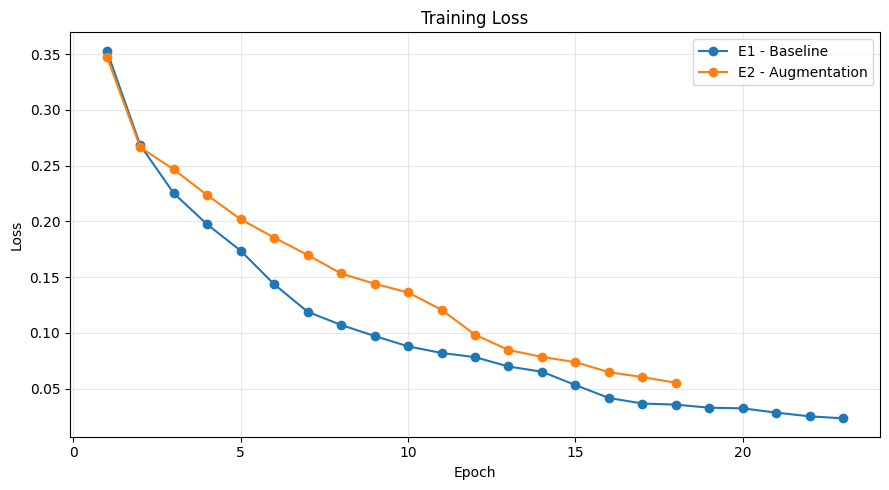

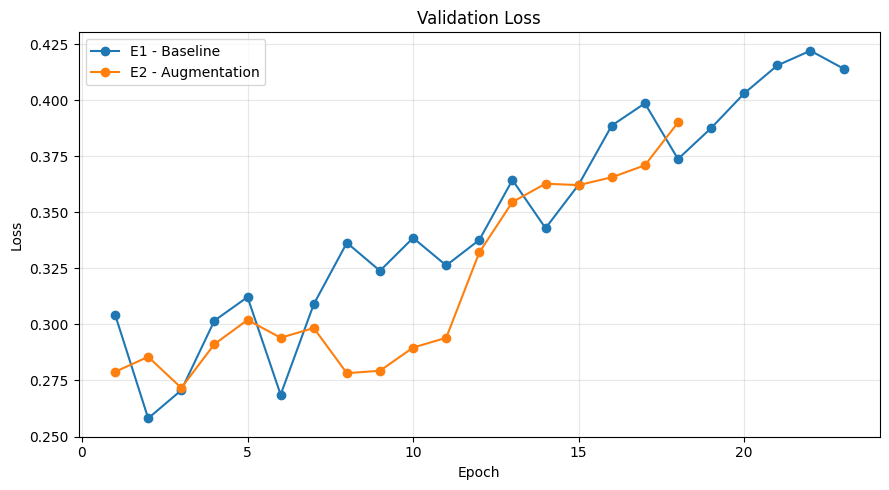

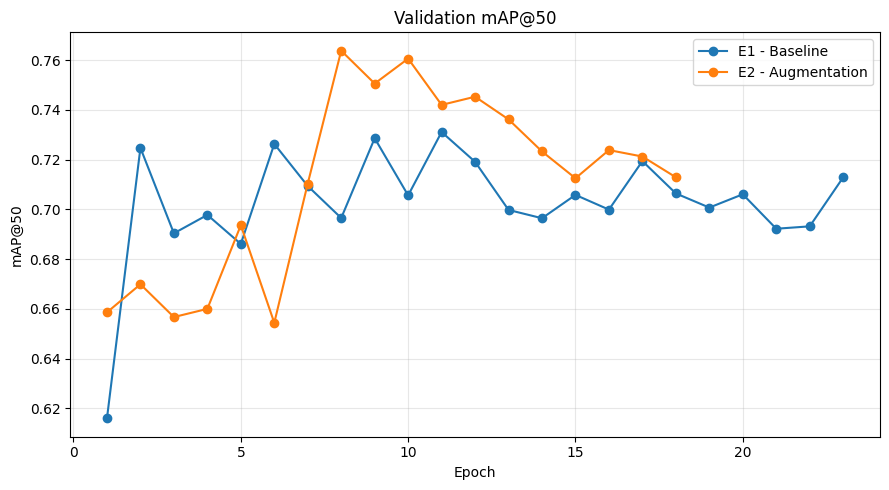

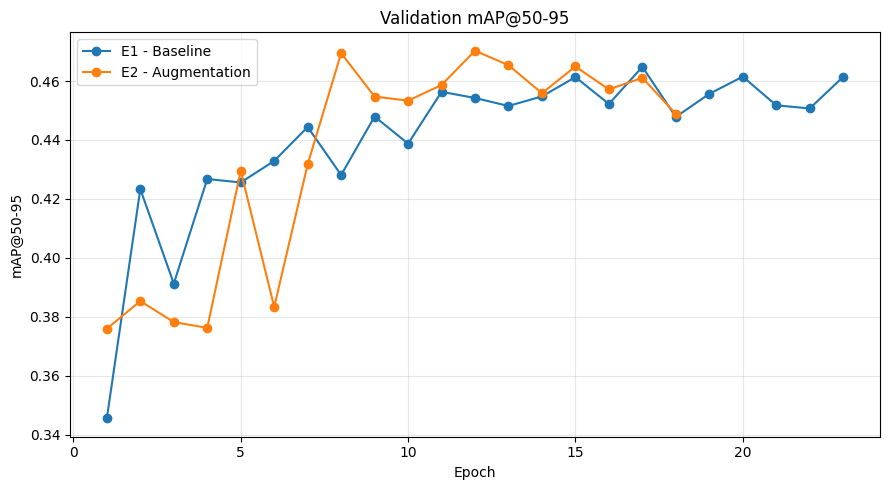

In [ ]:
import matplotlib.pyplot as plt

# Plot configuration
experiments = {
    "E1 - Baseline": history_e1,
    "E2 - Augmentation": history_e2
}

metrics = [
    ("train_loss", "Training Loss", "Loss"),
    ("val_loss", "Validation Loss", "Loss"),
    ("map_50", "Validation mAP@50", "mAP@50"),
    ("map_50_95", "Validation mAP@50-95", "mAP@50-95")
]

for metric, title, ylabel in metrics:
    plt.figure(figsize=(9, 5))

    for name, df in experiments.items():
        plt.plot(
            df["epoch"],
            df[metric],
            marker="o",
            label=name
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

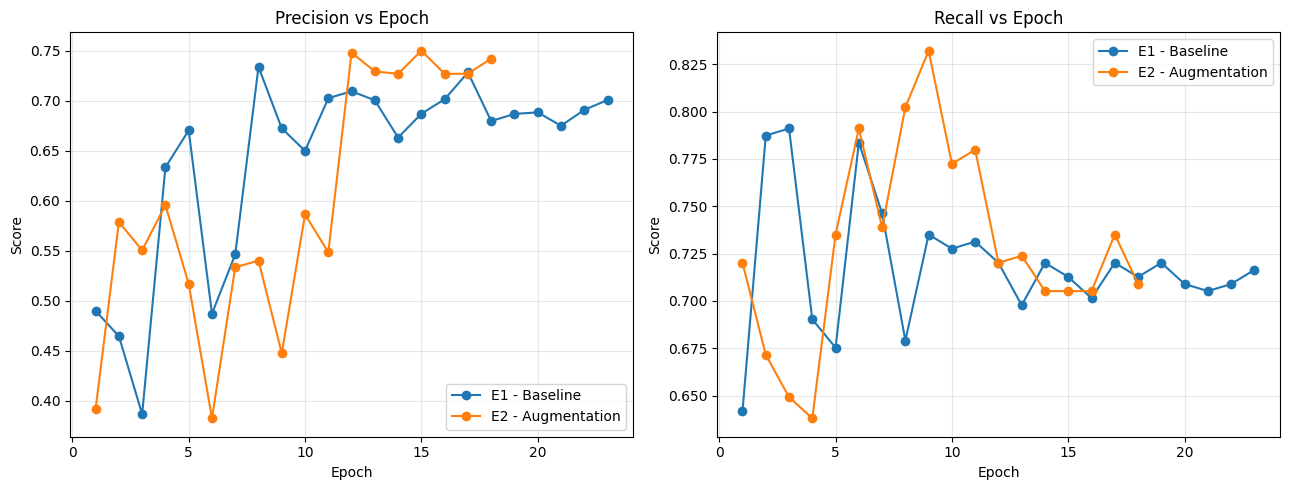

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, df in experiments.items():
    axes[0].plot(df["epoch"], df["precision"],
                 marker="o", label=name)

    axes[1].plot(df["epoch"], df["recall"],
                 marker="o", label=name)

axes[0].set_title("Precision vs Epoch")
axes[1].set_title("Recall vs Epoch")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 10.4 Quantitative Experiment Comparison

The best validation results from both experiments are summarized below.

| Metric | E1 – Baseline | E2 – Augmentation |
|---|---:|---:|
| Best epoch | 17 | 12 |
| Precision | 0.7283 | 0.7481 |
| Recall | 0.7201 | 0.7201 |
| mAP@50 | 0.7194 | 0.7453 |
| mAP@50–95 | 0.4648 | 0.4703 |

### Key Observations

- Experiment 2 achieves higher validation precision.
- Recall is the same for both selected checkpoints.
- Experiment 2 achieves higher validation mAP@50.
- Experiment 2 achieves a slightly higher validation mAP@50–95.
- The improvement in mAP@50–95 is modest rather than substantial.

The results suggest that data augmentation provides a small improvement in the validation performance of the Faster R-CNN model.

These results are used to identify the better-performing experiment before final evaluation.



# 11. Final Model Selection

The best model is selected based on validation mAP@50–95.

Experiment 2 achieves a validation mAP@50–95 of 0.4703, compared with 0.4648 for Experiment 1.

Although the improvement is relatively small, Experiment 2 provides the better validation result.

Therefore, the best checkpoint from Experiment 2 is selected as the final model.

The saved checkpoint contains the trained model state and associated training information. The model architecture is reconstructed with the same two-class Faster R-CNN configuration before loading the saved model weights.

The selected model is placed in evaluation mode before final inference.

The test dataset is not used for model selection or hyperparameter tuning.


In [ ]:
import torch
import os

checkpoint = torch.load(
    E2_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully.")

print("\nCheckpoint keys:")
print(checkpoint.keys())

print("\nBest validation mAP:", checkpoint.get("best_map"))

print("\nModel state dictionary present:",
      "model_state_dict" in checkpoint)

if "model_state_dict" in checkpoint:
    print("Number of model parameters:",
          len(checkpoint["model_state_dict"]))

Checkpoint loaded successfully.

Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_map', 'history'])

Best validation mAP: 0.4702899754047394

Model state dictionary present: True
Number of model parameters: 295


In [ ]:
import torchvision

print("Torchvision version:", torchvision.__version__)

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

print("Faster R-CNN imports: successful")
print("Device:", torch.device("cpu"))

Torchvision version: 0.29.1+cpu
Faster R-CNN imports: successful
Device: cpu


In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Recreate the same architecture with 2 classes:
# Background + Pothole

model_final = fasterrcnn_resnet50_fpn(weights=None)

in_features = model_final.roi_heads.box_predictor.cls_score.in_features

model_final.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, 2
)

model_final.to("cpu")

print("Faster R-CNN architecture created successfully.")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 92.6MB/s]


Faster R-CNN architecture created successfully.


In [ ]:
model_final.load_state_dict(checkpoint["model_state_dict"])

model_final.eval()

print("E2 model weights loaded successfully.")
print("Model is in evaluation mode:", not model_final.training)

total_params = sum(p.numel() for p in model_final.parameters())

print("Total parameters:", f"{total_params:,}")
print("Device: CPU")

E2 model weights loaded successfully.
Model is in evaluation mode: True
Total parameters: 41,299,161
Device: CPU



# 12. Final Evaluation on the Test Set

After selecting the best checkpoint using validation performance, the final model is evaluated on the held-out test dataset.

The test set contains 133 images and 299 annotated pothole instances.

The test set is kept untouched during training, experiment comparison, and checkpoint selection. It is used only for this final evaluation.

The selected Experiment 2 checkpoint is loaded and evaluated in inference mode.

## 12.1 Evaluation Procedure

For each test image:

1. The image is passed through the trained Faster R-CNN model.
2. The model generates predicted bounding boxes, class labels, and confidence scores.
3. Predictions and ground-truth annotations are compared.
4. Detection metrics are calculated using TorchMetrics.

Precision and recall are calculated using predictions with a confidence threshold of 0.5 and an IoU matching threshold of 0.5. Matching is performed using a greedy matching procedure, with each ground-truth object matched at most once.

mAP is calculated using the MeanAveragePrecision implementation with bounding-box format `xyxy` and IoU thresholds from 0.50 to 0.95.

No further training or model selection is performed using the test results.


In [ ]:
# Evaluation-only environment setup

import os
import torch
import torchvision
import numpy as np
import pandas as pd
from PIL import Image
import xml.etree.ElementTree as ET

from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = "/content/drive/MyDrive/road_data_shared"

print("Drive mounted:", os.path.exists(DATASET_PATH))
print("Dataset folders:", os.listdir(DATASET_PATH))
print("PyTorch:", torch.__version__)
print("Device: CPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted: True
Dataset folders: ['images', 'annotations', 'split_manifest.json', 'yolo_dataset', 'labels']
PyTorch: 2.14.1+cpu
Device: CPU


In [ ]:
import glob
import xml.etree.ElementTree as ET
from PIL import Image
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader

class EvaluationRoadDamageDataset(Dataset):

    def __init__(self, root_dir, split="test"):
        self.image_dir = os.path.join(root_dir, "images", split)
        self.annotation_dir = os.path.join(root_dir, "annotations", split)

        self.xml_files = sorted(
            glob.glob(os.path.join(self.annotation_dir, "*.xml"))
        )

        self.image_extensions = [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]

        if len(self.xml_files) == 0:
            raise RuntimeError("No XML annotations found.")

        print(f"{split} dataset initialized: {len(self.xml_files)} images")

    def __len__(self):
        return len(self.xml_files)

    def __getitem__(self, idx):

        xml_path = self.xml_files[idx]
        filename = os.path.splitext(os.path.basename(xml_path))[0]

        image_path = None

        for ext in self.image_extensions:
            candidate = os.path.join(self.image_dir, filename + ext)
            if os.path.exists(candidate):
                image_path = candidate
                break

        if image_path is None:
            raise FileNotFoundError(f"Image not found for {filename}")

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        tree = ET.parse(xml_path)
        root = tree.getroot()

        boxes = []

        for obj in root.findall("object"):
            bndbox = obj.find("bndbox")

            if bndbox is None:
                continue

            xmin = float(bndbox.find("xmin").text)
            ymin = float(bndbox.find("ymin").text)
            xmax = float(bndbox.find("xmax").text)
            ymax = float(bndbox.find("ymax").text)

            if xmax <= xmin or ymax <= ymin:
                continue

            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)

        labels = torch.ones((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": (boxes[:, 2] - boxes[:, 0]) *
                    (boxes[:, 3] - boxes[:, 1]),
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64)
        }

        image = TF.to_tensor(image)

        return image, target


def evaluation_collate_fn(batch):
    return tuple(zip(*batch))

print("Evaluation-only dataset class defined successfully.")

Evaluation-only dataset class defined successfully.


In [ ]:
test_dataset_final = EvaluationRoadDamageDataset(
    DATASET_PATH, split="test"
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    collate_fn=evaluation_collate_fn
)

print("\nTest images:", len(test_dataset_final))
print("Test batches:", len(test_loader_final))
print("Augmentation: Disabled")

test dataset initialized: 133 images

Test images: 133
Test batches: 67
Augmentation: Disabled


In [ ]:
!pip install torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [ ]:
import torchmetrics
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("TorchMetrics version:", torchmetrics.__version__)
print("MeanAveragePrecision imported successfully!")
print("Model loaded:", model_final is not None)
print("Model in evaluation mode:", not model_final.training)
print("Device:", next(model_final.parameters()).device)

TorchMetrics version: 1.9.0
MeanAveragePrecision imported successfully!
Model loaded: True
Model in evaluation mode: True
Device: cpu


In [ ]:
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from tqdm.auto import tqdm

def final_test_evaluation(model, data_loader, device="cpu"):

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    TP, FP, FN = 0, 0, 0

    with torch.inference_mode():

        for images, targets in tqdm(
            data_loader, desc="Final Test Evaluation"
        ):

            images = [img.to(device) for img in images]
            predictions = model(images)

            predictions_cpu = []
            targets_cpu = []

            for pred, target in zip(predictions, targets):

                pred_cpu = {
                    k: v.detach().cpu() for k, v in pred.items()
                }
                target_cpu = {
                    k: v.detach().cpu() for k, v in target.items()
                }

                predictions_cpu.append(pred_cpu)
                targets_cpu.append(target_cpu)

                keep = pred_cpu["scores"] >= 0.5

                pred_boxes = pred_cpu["boxes"][keep]
                pred_labels = pred_cpu["labels"][keep]

                gt_boxes = target_cpu["boxes"]
                gt_labels = target_cpu["labels"]

                matched_gt = set()

                if len(pred_boxes) > 0 and len(gt_boxes) > 0:

                    ious = box_iou(pred_boxes, gt_boxes)

                    order = torch.argsort(
                        pred_cpu["scores"][keep],
                        descending=True
                    )

                    for pred_idx in order.tolist():

                        candidates = [
                            j for j in range(len(gt_boxes))
                            if pred_labels[pred_idx] == gt_labels[j]
                            and j not in matched_gt
                        ]

                        if not candidates:
                            FP += 1
                            continue

                        best_gt = max(
                            candidates,
                            key=lambda j: ious[pred_idx, j].item()
                        )

                        if ious[pred_idx, best_gt] >= 0.5:
                            TP += 1
                            matched_gt.add(best_gt)
                        else:
                            FP += 1

                else:
                    FP += len(pred_boxes)

                FN += len(gt_boxes) - len(matched_gt)

            metric.update(predictions_cpu, targets_cpu)

    results = metric.compute()

    return {
        "Precision": TP / (TP + FP) if TP + FP else 0.0,
        "Recall": TP / (TP + FN) if TP + FN else 0.0,
        "mAP@50": results["map_50"].item(),
        "mAP@50-95": results["map"].item(),
        "True Positives": TP,
        "False Positives": FP,
        "False Negatives": FN
    }

print("Final evaluation function defined successfully.")

Final evaluation function defined successfully.


In [ ]:
import time

start_time = time.time()

test_results = final_test_evaluation(
    model_final,
    test_loader_final,
    device="cpu"
)

evaluation_time = time.time() - start_time

print("\n========== FINAL TEST RESULTS ==========")

for name, value in test_results.items():
    print(f"{name}: {value:.4f}" if isinstance(value, float)
          else f"{name}: {value}")

print(f"\nEvaluation time: {evaluation_time / 60:.2f} minutes")

results_path = os.path.join(
    BASE_DIR, "experiment2_final_test_results.csv"
)

pd.DataFrame([test_results]).to_csv(results_path, index=False)

print("\nResults saved:", results_path)

Final Test Evaluation:   0%|          | 0/67 [00:00<?, ?it/s]


========== FINAL TEST RESULTS ==========
Precision: 0.7404
Recall: 0.7726
mAP@50: 0.7561
mAP@50-95: 0.4689
True Positives: 231
False Positives: 81
False Negatives: 68

Evaluation time: 20.42 minutes

Results saved: /content/drive/MyDrive/FasterRCNN_Checkpoints/experiment2_final_test_results.csv



## 12.2 Final Test Results

The selected Experiment 2 model achieves the following results on the held-out test dataset:

| Metric | Test Result |
|---|---:|
| Precision | 0.7404 |
| Recall | 0.7726 |
| mAP@50 | 0.7561 |
| mAP@50–95 | 0.4689 |
| True Positives | 231 |
| False Positives | 81 |
| False Negatives | 68 |
| F1-score | 0.7565 |

The F1-score is calculated from the reported precision and recall.

### Interpretation

The model achieves a test mAP@50 of 0.7561 and mAP@50–95 of 0.4689.

The precision of 0.7404 indicates that a substantial proportion of the model's detections are correct, while the recall of 0.7726 indicates that the model detects a substantial proportion of the annotated potholes.

The difference between validation mAP@50–95 (0.4703) and test mAP@50–95 (0.4689) is small, indicating consistent performance across the validation and test subsets.

These results represent the final evaluation of the selected checkpoint.


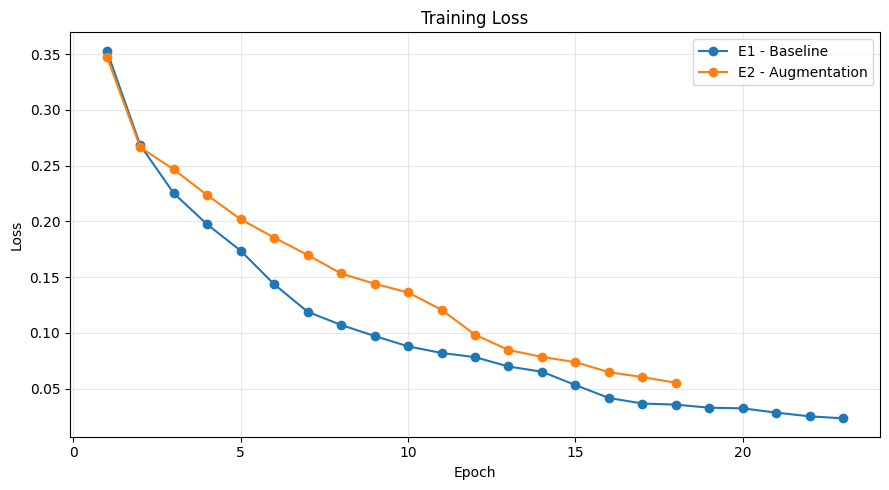

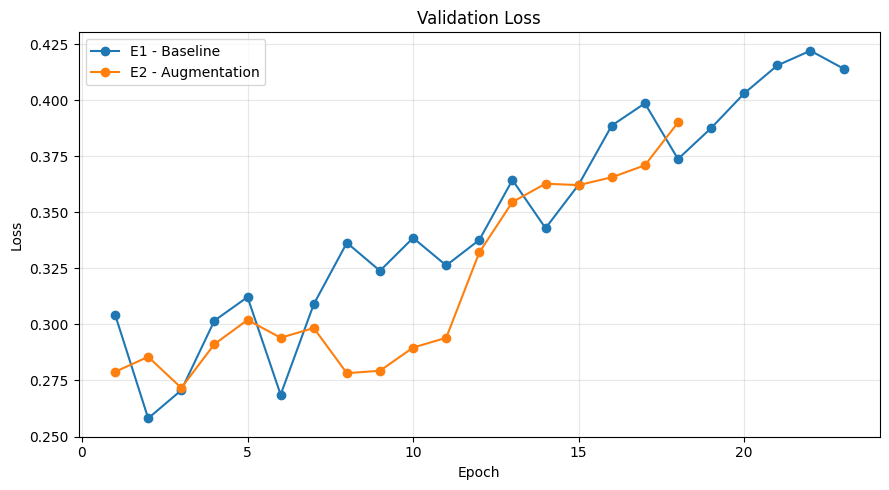

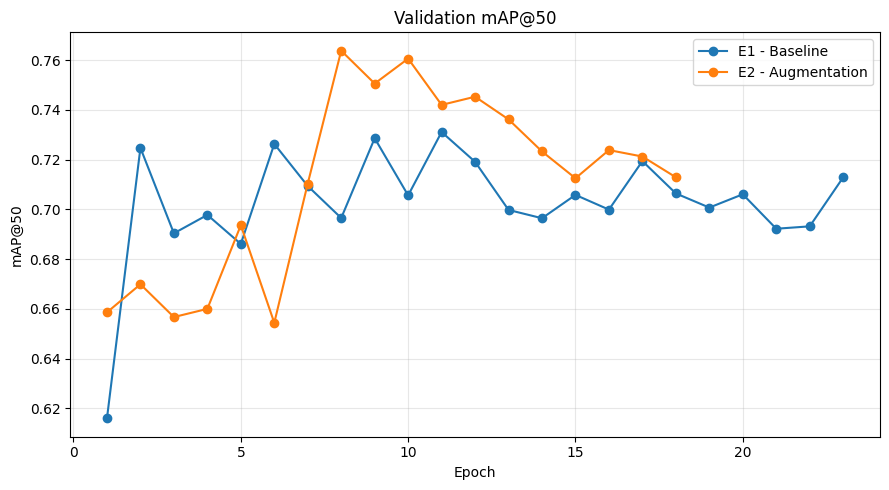

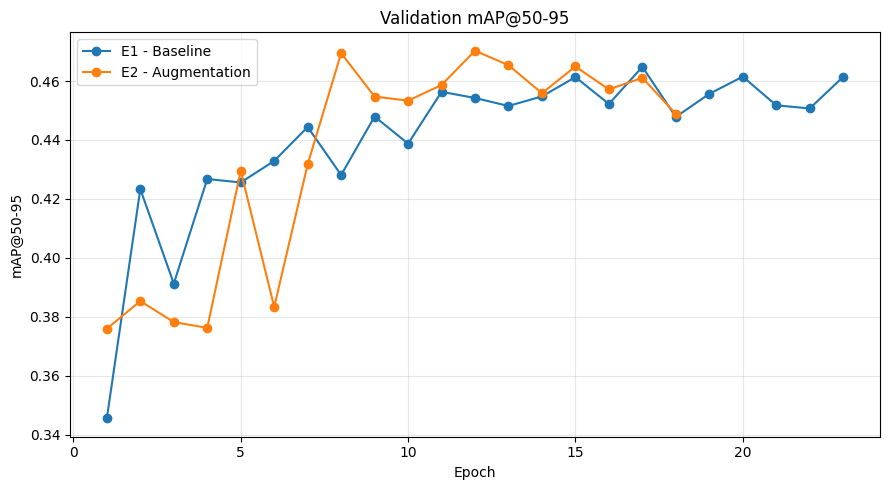

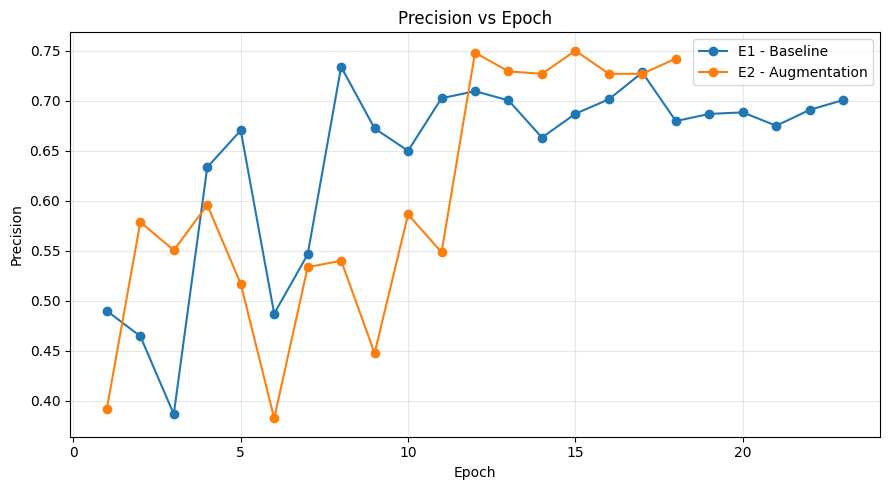

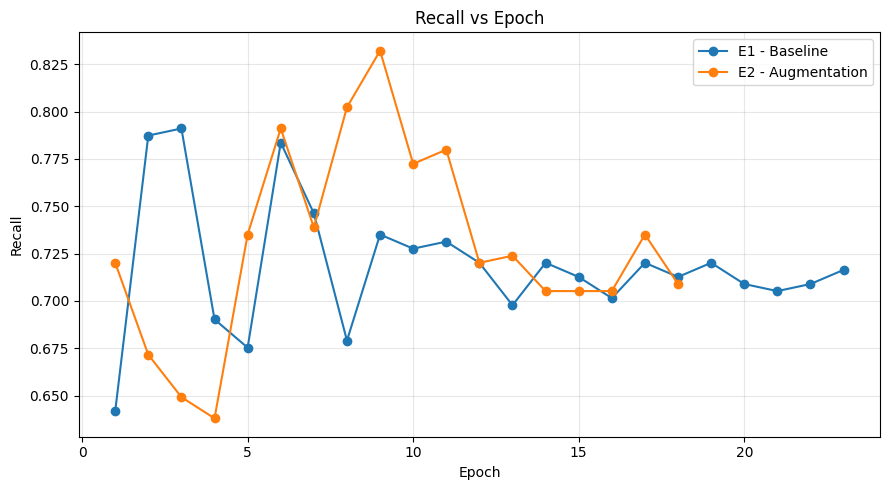

All six plots saved to: /content/drive/MyDrive/FasterRCNN_Checkpoints/Experiment_Plots


In [ ]:
import os
import matplotlib.pyplot as plt

PLOTS_DIR = os.path.join(BASE_DIR, "Experiment_Plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

experiments = {
    "E1 - Baseline": history_e1,
    "E2 - Augmentation": history_e2
}

plot_metrics = [
    ("train_loss", "Training Loss", "Loss"),
    ("val_loss", "Validation Loss", "Loss"),
    ("map_50", "Validation mAP@50", "mAP@50"),
    ("map_50_95", "Validation mAP@50-95", "mAP@50-95"),
    ("precision", "Precision vs Epoch", "Precision"),
    ("recall", "Recall vs Epoch", "Recall")
]

for metric, title, ylabel in plot_metrics:

    plt.figure(figsize=(9, 5))

    for name, df in experiments.items():
        plt.plot(
            df["epoch"],
            df[metric],
            marker="o",
            label=name
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = metric + ".png"

    plt.savefig(
        os.path.join(PLOTS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All six plots saved to:", PLOTS_DIR)

In [ ]:
experiment_summary = pd.DataFrame([
    {
        "Experiment": "E1 - Baseline",
        "Best Epoch": 17,
        "Best Validation Precision": 0.7283,
        "Best Validation Recall": 0.7201,
        "Best Validation mAP50": 0.7194,
        "Best Validation mAP50-95": 0.4648
    },
    {
        "Experiment": "E2 - Augmentation",
        "Best Epoch": 12,
        "Best Validation Precision": 0.7481,
        "Best Validation Recall": 0.7201,
        "Best Validation mAP50": 0.7453,
        "Best Validation mAP50-95": 0.4703
    }
])

experiment_summary.to_csv(
    os.path.join(BASE_DIR, "experiment_comparison.csv"),
    index=False
)

print("EXPERIMENT COMPARISON")
display(experiment_summary)

print("\nFINAL TEST RESULTS")
display(pd.DataFrame([test_results]))

print("\nAll experiment summaries saved successfully.")

EXPERIMENT COMPARISON


,Experiment,Best Epoch,Best Validation Precision,Best Validation Recall,Best Validation mAP50,Best Validation mAP50-95
0,E1 - Baseline,17,0.7283,0.7201,0.7194,0.4648
1,E2 - Augmentation,12,0.7481,0.7201,0.7453,0.4703



FINAL TEST RESULTS


,Precision,Recall,mAP@50,mAP@50-95,True Positives,False Positives,False Negatives
0,0.740385,0.772575,0.756083,0.468874,231,81,68



All experiment summaries saved successfully.



# 13. Prediction Visualization

To qualitatively examine the performance of the selected Faster R-CNN model, predictions are visualized on sample validation images.

The model generates bounding boxes and confidence scores for detected potholes.

The predicted bounding boxes are compared with the ground-truth annotations.

### Visualization Legend

- **Green bounding boxes:** Ground-truth pothole locations.
- **Red bounding boxes:** Model-predicted pothole locations.
- **Confidence scores:** Model confidence associated with each predicted detection.

A confidence threshold of 0.5 is applied for displaying predicted bounding boxes.

These visualizations provide an intuitive understanding of how accurately the model identifies and localizes potholes.

### Observations

The visualizations demonstrate that the model can identify potholes of different sizes and appearances.

Some predicted bounding boxes overlap closely with the ground-truth annotations, while other detections show localization differences or additional predictions.

These examples illustrate both the strengths and limitations of the trained detector.

The displayed images are selected from the validation dataset. The held-out test dataset is not used for qualitative visualization or further model tuning.


In [ ]:
val_dataset_final = EvaluationRoadDamageDataset(
    DATASET_PATH,
    split="val"
)

print("Validation images:", len(val_dataset_final))

val dataset initialized: 106 images
Validation images: 106


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import random
import numpy as np

model_final.eval()

# Use validation dataset, not test dataset
visualization_indices = [0, 5, 10, 15, 20, 25]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for ax, idx in zip(axes, visualization_indices):

    image, target = val_dataset_final[idx]

    with torch.inference_mode():
        prediction = model_final([image])[0]

    image_np = image.permute(1, 2, 0).numpy()

    ax.imshow(image_np)

    # Ground-truth boxes: green
    for box in target["boxes"]:
        x1, y1, x2, y2 = box.tolist()

        rect = patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

    # Predicted boxes: red, confidence >= 0.5
    keep = prediction["scores"] >= 0.5

    for box, score in zip(
        prediction["boxes"][keep],
        prediction["scores"][keep]
    ):
        x1, y1, x2, y2 = box.tolist()

        rect = patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
        ax.add_patch(rect)

        ax.text(
            x1, max(0, y1-5),
            f"{score.item():.2f}",
            color="white",
            fontsize=9,
            bbox=dict(facecolor="red", alpha=0.7)
        )

    ax.set_title(f"Validation Image {idx}")
    ax.axis("off")

plt.tight_layout()

visualization_path = os.path.join(
    BASE_DIR, "validation_predictions.png"
)

plt.savefig(visualization_path, dpi=300, bbox_inches="tight")
plt.show()

print("Visualization saved:", visualization_path)

Output hidden; open in https://colab.research.google.com to view.


# 14. Model Efficiency Analysis

In addition to detection accuracy, the computational efficiency of the selected model is examined.

The analysis considers inference time, throughput, parameter count, estimated parameter memory, and checkpoint file size.

## 14.1 Inference Time

Inference time is measured using the selected Experiment 2 model on a CPU-only runtime.

Two warm-up inferences are performed before measurement. The model is then evaluated on 10 validation images individually.

The time required for model inference is recorded for each image.

The average and median inference times are calculated, along with throughput in images per second.

The benchmark measures model inference time after the image has been loaded into memory. It does not include dataset loading or image preprocessing time.

## 14.2 Model Complexity

The total number of model parameters and trainable parameters are calculated.

The estimated FP32 parameter memory is calculated by assuming four bytes per parameter.

The saved checkpoint file size is also measured. This checkpoint contains model weights and additional training-related information, so its file size is different from the estimated model weight memory.

## 14.3 Efficiency Results

| Metric | Result |
|---|---:|
| Model | Faster R-CNN ResNet-50 FPN |
| Total parameters | 41,299,161 |
| Trainable parameters | 41,076,761 |
| Estimated FP32 weight memory | 157.54 MB |
| Checkpoint file size | 314.78 MB |
| Average inference time | 6.466 seconds/image |
| Median inference time | 6.027 seconds/image |
| Throughput | 0.155 images/second |
| Benchmark device | CPU |
| Benchmark images | 10 |

### Observations

Faster R-CNN provides object detection capabilities with a relatively large number of model parameters.

The measured CPU inference time indicates that the model is computationally demanding when executed without GPU acceleration.

The parameter count and inference-time measurements provide useful information about the computational requirements of deploying the model in practical applications.


In [ ]:

import time
import numpy as np
import torch

model_final.eval()

# Warm-up
with torch.inference_mode():
    for i in range(2):
        image, _ = val_dataset_final[i]
        _ = model_final([image])

# Benchmark 10 validation images
inference_times = []

with torch.inference_mode():
    for i in range(10):
        image, _ = val_dataset_final[i]

        start_time = time.perf_counter()
        _ = model_final([image])
        elapsed = time.perf_counter() - start_time

        inference_times.append(elapsed)

avg_time = np.mean(inference_times)
median_time = np.median(inference_times)

print(f"Average inference time: {avg_time:.3f} seconds/image")
print(f"Median inference time:  {median_time:.3f} seconds/image")
print(f"Throughput:             {1/avg_time:.3f} images/second")
print("Images benchmarked:     10")
print("Device:                 CPU")


Average inference time: 6.466 seconds/image
Median inference time:  6.027 seconds/image
Throughput:             0.155 images/second
Images benchmarked:     10
Device:                 CPU


In [ ]:

import os

total_params = sum(p.numel() for p in model_final.parameters())
trainable_params = sum(
    p.numel() for p in model_final.parameters() if p.requires_grad
)

# FP32 parameter memory estimate
parameter_memory_mb = total_params * 4 / (1024 ** 2)

# Complete checkpoint size (includes more than just model weights)
checkpoint_size_mb = os.path.getsize(E2_CHECKPOINT) / (1024 ** 2)

print(f"Total parameters:          {total_params:,}")
print(f"Trainable parameters:      {trainable_params:,}")
print(f"Estimated FP32 weights:    {parameter_memory_mb:.2f} MB")
print(f"Checkpoint file size:      {checkpoint_size_mb:.2f} MB")


Total parameters:          41,299,161
Trainable parameters:      41,076,761
Estimated FP32 weights:    157.54 MB
Checkpoint file size:      314.78 MB



# 15. Conclusion

This project presents a deep learning-based approach for automated pothole detection using Faster R-CNN with a ResNet-50 Feature Pyramid Network backbone.

A custom PyTorch dataset pipeline was developed to process road images and their Pascal VOC XML annotations. The model was initialized with COCO pretrained weights and fine-tuned for the pothole detection task.

Two experiments were conducted to investigate the effect of data augmentation.

The baseline experiment achieved a validation mAP@50–95 of 0.4648, while the augmentation experiment achieved 0.4703.

Based on validation performance, the best checkpoint from Experiment 2 was selected for final testing.

The selected model achieved the following results on the held-out test set:

- Precision: 0.7404
- Recall: 0.7726
- mAP@50: 0.7561
- mAP@50–95: 0.4689
- F1-score: 0.7565

The small difference between validation and test mAP@50–95 indicates that the selected model maintains relatively consistent detection performance on the held-out test data.

Prediction visualizations further demonstrate the model's ability to identify and localize potholes in road images.

The efficiency analysis shows that the model contains approximately 41.3 million parameters and requires an average of 6.466 seconds per image in the measured CPU inference benchmark.

Overall, the project demonstrates the application of transfer learning and object detection techniques to road damage analysis. It also highlights the importance of data preprocessing, augmentation, validation-based checkpoint selection, and independent test evaluation.

# 16. Limitations

The current implementation has the following limitations:

1. **Single-class detection:** The model is trained to detect potholes only and does not classify other types of road damage.
2. **Dataset size:** The experiments use a dataset containing 665 images, which limits the diversity of training examples.
3. **Localization errors:** Some predicted bounding boxes do not perfectly overlap with ground-truth annotations.
4. **Computational requirements:** Faster R-CNN has a relatively large parameter count and high CPU inference latency.
5. **Environmental variations:** Changes in lighting, road texture, camera angle, and image quality may affect detection performance.
6. **Annotation limitations:** The dataset undergoes basic annotation validity checks, but an exhaustive manual audit of annotation completeness has not been performed.

# 17. Future Scope

The project can be extended in several directions:

- Extend detection to multiple categories of road damage, such as cracks and other surface defects.
- Increase dataset size and diversity using additional road images.
- Investigate more advanced augmentation techniques.
- Explore lightweight object detection architectures for faster inference.
- Optimize the trained model for GPU and edge-device deployment.
- Integrate the detection system with a mobile camera or vehicle-mounted camera for real-time road inspection.
- Develop a road damage monitoring system that stores detected pothole locations for maintenance planning.

# 18. Final Remarks

The experiments demonstrate that Faster R-CNN can be applied to automated pothole detection using annotated road images.

The comparison between baseline training and augmentation-based training provides insight into the effect of data augmentation on detection performance.

The final evaluation, prediction visualizations, and efficiency analysis provide a quantitative and qualitative assessment of the developed model.
